<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/19.Reinforcement_Learning_from_Human_Feedback.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 19 — Reinforcement Learning from Human Feedback

*LLM Design Patterns* · notebook pendamping, edisi Colab GPU

Bayangkan kita punya GPT-2 yang pandai melanjutkan kalimat, dan kita ingin lanjutannya bernada positif. Aturan "tulis yang positif" sulit dikodekan langsung. Yang jauh lebih mudah adalah **menilai**: dari dua lanjutan, mana yang lebih baik? RLHF memanfaatkan kemudahan itu. Penilaian (idealnya dari manusia) dipakai untuk melatih **reward model**, lalu model bahasa didorong ke arah teks yang diberi reward tinggi.

Buku membangun bab ini dari tiga komponen, yaitu base model, reward model, dan optimasi *policy* (model yang dilatih) dengan PPO, lalu DPO, strategi skala, keterbatasan seperti *reward hacking*, dan penerapan untuk meringkas teks. Listing buku yang rusak ditunjukkan di kotak **Listing buku** beserta error yang teramati, lalu disusul versi yang berjalan. Empat eksperimen *Under the hood* (UTH) menguji klaim yang bisa diukur:

| UTH | Pertanyaan |
|---|---|
| 1 | Reward model dari perbandingan: label per teks (cara listing buku) atau per pasangan? Dan apakah ia lebih baik dari aturan "pilih jawaban yang lebih panjang"? |
| 2 | Apa yang terjadi pada loop RL bila penalti KL (rem yang menjaga model tetap dekat model awal) dibuang? |
| 3 | DPO lawan loop RL pada tugas yang sama |
| 4 | Apakah batasan "lewati update" dari buku mencegah reward hacking? |

> **Catatan sebelum mulai**
>
> - Reward di loop RL adalah **pengganti**: classifier sentimen DistilBERT SST-2, bukan reward model dari preferensi manusia. Data preferensi manusia yang sebenarnya (HH-RLHF) dipakai di bagian reward model.
> - Notebook ini disiapkan untuk Colab dengan GPU (T4 cukup), tetapi **belum pernah dijalankan di GPU/Colab** oleh penyusunnya. Versi kecilnya (opt-in CPU) sudah dijalankan dari awal sampai akhir di CPU lokal; itu memeriksa urutan sel dan API, bukan jalur CUDA.
> - Angka di narasi berasal dari *run referensi*, yaitu eksekusi versi sebelumnya notebook ini di CPU dengan desain yang sama (kecuali bagian skala, yang di GPU memakai gpt2-large). Eksperimen UTH juga dijalankan sekali dalam ukuran penuh dengan kode versi ini di CPU lain (*run validasi*); perbedaan pentingnya dibahas di UTH-2 dan UTH-4. Bagian deterministik (data, tokenisasi, decoding greedy yang selalu memilih token paling mungkin, fitur model yang dibekukan) seharusnya memberi angka yang sama; loop RL dan DPO memakai sampling dan kernel CUDA yang tidak deterministik, jadi bandingkan polanya, bukan digitnya.

## Persiapan

Colab sudah membawa torch, transformers, datasets, scikit-learn, NLTK, dan matplotlib; yang perlu dipasang hanya TRL (pustaka untuk DPO), dipin ke versi yang dipakai saat menyusun notebook ini.

In [1]:
import importlib.metadata
import subprocess
import sys

TRL_VERSION = "1.14.2"
try:
    trl_installed = importlib.metadata.version("trl")
except importlib.metadata.PackageNotFoundError:
    trl_installed = None
if trl_installed != TRL_VERSION:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"trl=={TRL_VERSION}"], check=True)
print("trl", importlib.metadata.version("trl"))

trl 1.14.2


**GPU dulu, sebelum memuat apa pun.** `torch.cuda.is_available()` saja belum cukup, karena GPU bisa terlihat tapi gagal saat dipakai. Sel berikut mengalokasikan matriks di GPU, mengalikannya, menunggu sampai selesai (`synchronize`), lalu mencetak nama GPU, compute capability, dan VRAM bebas. Kalau gagal, notebook berhenti dengan petunjuk yang sesuai. CPU hanya dipakai bila Anda sengaja menyetel `ALLOW_CPU = True`, dan saat itu ukuran eksperimen otomatis diperkecil agar tidak berjalan berjam-jam.

Compute capability menentukan presisi demo *mixed precision* di bagian skala: fp16 di T4 (7.5), bf16 di GPU Ampere ke atas. Eksperimen RL dan DPO selalu berjalan dalam fp32.

In [2]:
import os

import torch

# Opt-in CPU harus disengaja: ganti baris ini dengan ALLOW_CPU = True (atau set env RLHF_ALLOW_CPU=1)
# hanya bila ingin menjalankan versi kecil di CPU.
ALLOW_CPU = os.environ.get("RLHF_ALLOW_CPU", "0") == "1"


def cuda_smoke_test():
    """Bukan cuma is_available(): alokasi, perkalian matriks, dan synchronize di GPU."""
    if not torch.cuda.is_available():
        return "torch.cuda.is_available() bernilai False"
    try:
        x = torch.randn(1024, 1024, device="cuda")
        y = x @ x.T
        torch.cuda.synchronize()
        if not torch.isfinite(y).all().item():
            return "hasil perkalian matriks di GPU tidak finite"
    except Exception as err:  # CUDA terlihat tapi tidak bisa dipakai
        return f"operasi CUDA gagal: {err}"
    return None


cuda_problem = cuda_smoke_test()
if cuda_problem is None:
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(DEVICE)
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print(f"GPU siap: {props.name} | compute capability {props.major}.{props.minor} | "
          f"VRAM bebas {free_bytes / 2**30:.1f} dari {total_bytes / 2**30:.1f} GiB")
elif ALLOW_CPU:
    DEVICE = torch.device("cpu")
    print(f"CUDA tidak dipakai ({cuda_problem}). ALLOW_CPU aktif: berjalan di CPU dengan ukuran eksperimen yang diperkecil.")
else:
    if torch.cuda.is_available():
        hint = ("GPU terdeteksi tapi sesi CUDA tidak bisa dipakai (mis. setelah device-side assert). "
                "Di Colab: Runtime > Restart session (atau Disconnect and delete runtime), lalu jalankan ulang dari atas.")
    else:
        hint = ("Di Colab: Runtime > Change runtime type > Hardware accelerator: GPU (mis. T4) > Save, "
                "lalu jalankan ulang dari atas.")
    raise RuntimeError(f"GPU CUDA tidak siap: {cuda_problem}.\n{hint}\n"
                       "Untuk sengaja menjalankan versi kecil di CPU, set ALLOW_CPU = True di sel ini.")

# T4 (compute capability 7.5) tidak punya bf16 native; demo mixed precision memakai fp16 di sana.
BF16_NATIVE = DEVICE.type == "cuda" and torch.cuda.get_device_capability(DEVICE)[0] >= 8
AMP_DTYPE = torch.float16 if DEVICE.type == "cuda" and not BF16_NATIVE else torch.bfloat16
amp_info = str(AMP_DTYPE).replace("torch.", "") if DEVICE.type == "cuda" else "dilewati di CPU"
print(f"device {DEVICE} | presisi eksperimen RL/DPO: fp32 | autocast di bagian skala: {amp_info}")

GPU siap: Tesla T4 | compute capability 7.5 | VRAM bebas 14.4 dari 14.6 GiB
device cuda | presisi eksperimen RL/DPO: fp32 | autocast di bagian skala: float16


Semua impor, ukuran eksperimen, dan dua helper ada di satu sel. `check_device` adalah audit kecil yang dipakai berulang kali: ia langsung menghentikan notebook dengan error bila ada parameter model yang tidak berada di `DEVICE`, sehingga model tak bisa diam-diam berjalan di CPU. `free_memory` melepas model yang sudah selesai dipakai sebelum eksperimen berikutnya.

In [3]:
import gc
import gzip
import hashlib
import json
import random
import re
import time
import urllib.request
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import nltk
import numpy as np
import sklearn
import transformers
import trl
from datasets import load_dataset
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.linear_model import LogisticRegression
from transformers import (AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification,
                          AutoTokenizer, GPT2LMHeadModel, Trainer, TrainingArguments)
from trl import DPOConfig, DPOTrainer

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
torch.manual_seed(42)
random.seed(42)

WORK_DIR = Path("rlhf_ch19_work")       # data dan output trainer bab ini
WORK_DIR.mkdir(exist_ok=True)

# Ukuran eksperimen: penuh di GPU; versi kecil di CPU opt-in (kecuali env RLHF_SIZE=full).
FULL = DEVICE.type == "cuda" or os.environ.get("RLHF_SIZE") == "full"
N_RM = 2000 if FULL else 200           # pasangan latih reward model UTH-1 (dari 43.835)
N_RM_TEST = None if FULL else 300      # None = seluruh 2.354 pasangan uji
RL_STEPS = 60 if FULL else 6           # langkah RL per lengan (UTH-2, UTH-4)
N_EVAL = 64 if FULL else 16            # prompt evaluasi, masing-masing 2 sampel
N_PAIR = 320 if FULL else 32           # prompt untuk data preferensi DPO (UTH-3)
GC_MODEL = "gpt2-large" if DEVICE.type == "cuda" else "gpt2"   # model listing gradient checkpointing


def free_memory():
    """Kumpulkan objek Python yang tak dirujuk lagi, lalu kembalikan cache allocator CUDA."""
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def check_device(**models):
    """Audit: semua parameter tiap model harus berada di DEVICE."""
    for name, model in models.items():
        found = {p.device.type for p in model.parameters()}
        if found != {DEVICE.type}:
            raise RuntimeError(f"{name} berada di {found}, bukan {DEVICE.type}")
    return ", ".join(f"{name} di {DEVICE.type}" for name in models)


print(f"ukuran eksperimen: {'penuh' if FULL else 'kecil (CPU)'} | torch {torch.__version__} | transformers {transformers.__version__} | "
      f"trl {trl.__version__} | datasets {datasets.__version__} | scikit-learn {sklearn.__version__} | nltk {nltk.__version__}")

ukuran eksperimen: penuh | torch 2.11.0+cu130 | transformers 5.20.2 | trl 1.14.2 | datasets 4.8.5 | scikit-learn 1.6.1 | nltk 3.9.1


**Bahan bab ini.** Data preferensi manusia adalah HH-RLHF *helpful-base* (Bai dkk. 2022): dialog yang diberi penilaian manusia, diunduh dari repo GitHub Anthropic dan dicocokkan dengan sha256 resminya. Dua dataset lain berperan pendukung: SST-2 (kalimat ulasan film) menjadi sumber prompt loop RL dan bahan uji reward model, sedangkan wikitext-2 menyediakan teks untuk bagian skala dan bagian meringkas.

In [4]:
# HH-RLHF disimpan lewat Git LFS: URL raw memberi pointer berisi sha256 resmi, URL media memberi isinya.
HH_POINTER = "https://raw.githubusercontent.com/anthropics/hh-rlhf/master/helpful-base"
HH_MEDIA = "https://media.githubusercontent.com/media/anthropics/hh-rlhf/master/helpful-base"
data_dir = WORK_DIR / "data"
data_dir.mkdir(exist_ok=True)
hh = {}
for split in ("train", "test"):
    path = data_dir / f"helpful-base-{split}.jsonl.gz"
    pointer = urllib.request.urlopen(f"{HH_POINTER}/{split}.jsonl.gz", timeout=60).read().decode()
    expected_sha = re.search(r"sha256:([0-9a-f]{64})", pointer).group(1)
    if not path.exists():
        urllib.request.urlretrieve(f"{HH_MEDIA}/{split}.jsonl.gz", path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected_sha:
        path.unlink()
        raise RuntimeError(f"sha256 HH-RLHF {split} tidak cocok dengan pointer LFS; jalankan ulang sel ini")
    with gzip.open(path, "rt") as f:
        hh[split] = [json.loads(line) for line in f]
print(f"HH-RLHF helpful-base: train {len(hh['train'])} pasangan, test {len(hh['test'])} pasangan (sha256 cocok)")

sst_tr = load_dataset("nyu-mll/glue", "sst2", split="train")
sst_val = load_dataset("nyu-mll/glue", "sst2", split="validation")
wiki_val = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="validation")
print(f"SST-2: train {len(sst_tr)}, validation {len(sst_val)} kalimat | wikitext-2 validation: {len(wiki_val)} baris")

HH-RLHF helpful-base: train 43835 pasangan, test 2354 pasangan (sha256 cocok)
SST-2: train 67349, validation 872 kalimat | wikitext-2 validation: 3760 baris


Dua model dipakai di hampir semua bagian. Yang pertama adalah **policy** kita, GPT-2 124M yang akan dilatih (dalam istilah RL, policy adalah model yang "memilih aksi", di sini token berikutnya); sel berikut memuat tokenizer-nya. Yang kedua, DistilBERT yang di-fine-tune pada SST-2, memberi skor sentimen, dan skor itu kita jadikan reward: **log-odds kelas positif**, yaitu logit positif dikurangi logit negatif. Nilai 0 berarti 50:50, sedangkan +4 berarti peluang positif sekitar 98%.

In [5]:
gpt_tok = AutoTokenizer.from_pretrained("gpt2")
SST2 = "distilbert-base-uncased-finetuned-sst-2-english"
sst2_tok = AutoTokenizer.from_pretrained(SST2)
sst2_clf = AutoModelForSequenceClassification.from_pretrained(SST2).to(DEVICE).eval()
print(check_device(sst2_clf=sst2_clf))

sst2_clf di cuda


## Komponen sistem RLHF

Buku membagi sistem RLHF menjadi tiga bagian: *base language model* (LLM pra-latih yang akan disesuaikan), *reward model* (memberi skor pada teks, dilatih dari preferensi manusia), dan *policy optimization* (memperbarui base model memakai skor itu). Kerangkanya menyatukan dua yang pertama dalam satu kelas dengan metode `generate_text` dan `get_reward`.

> **Listing buku: `RLHFSystem` — perlu diperbaiki**
>
> ```python
> from transformers import AutoModelForCausalLM, AutoTokenizer
> self.reward_model = AutoModelForSequenceClassification.from_pretrained(reward_model_name)
> self.tokenizer = AutoTokenizer.from_pretrained(base_model_name)
> outputs = self.base_model.generate(inputs, max_length=100)
> outputs = self.reward_model(inputs)   # inputs dari self.tokenizer, milik base model
> return outputs.logits.item()
> ```
>
> Dijalankan apa adanya, konstruktornya berhenti di `NameError`: `AutoModelForSequenceClassification` tidak diimpor. Setelah itu muncul tiga error lagi: `generate(inputs)` dan `reward_model(inputs)` sama-sama menerima `BatchEncoding` utuh di posisi tensor (`AttributeError` dan `TypeError`), dan `.item()` gagal (`RuntimeError: a Tensor with 2 elements cannot be converted to Scalar`) karena classifier dua kelas mengeluarkan dua logit. Masalah paling halus ada di tokenizer: teks untuk reward model ditokenisasi dengan tokenizer GPT-2. Sebagian kalimat berakhir dengan error, sisanya lolos dengan skor tak bermakna (diukur di bawah). Versi yang berjalan ada di sel berikut.

Perbaikannya mempertahankan struktur buku dengan empat perubahan: import lengkap, `**inputs`, tokenizer milik reward model sendiri, dan satu skor dari dua logit (log-odds positif), dengan model dan setiap input di GPU.

In [6]:
class RLHFSystem:
    """Kerangka buku, diperbaiki: import lengkap, **inputs, tokenizer milik reward model, reward skalar, semuanya di DEVICE."""

    def __init__(self, base_model_name, reward_model_name):
        self.base_model = AutoModelForCausalLM.from_pretrained(base_model_name).to(DEVICE).eval()
        self.reward_model = AutoModelForSequenceClassification.from_pretrained(reward_model_name).to(DEVICE).eval()
        self.tokenizer = AutoTokenizer.from_pretrained(base_model_name)
        self.reward_tokenizer = AutoTokenizer.from_pretrained(reward_model_name)

    @torch.no_grad()
    def generate_text(self, prompt):
        inputs = self.tokenizer(prompt, return_tensors="pt").to(DEVICE)
        outputs = self.base_model.generate(**inputs, max_length=100, pad_token_id=self.tokenizer.eos_token_id)
        return self.tokenizer.decode(outputs[0], skip_special_tokens=True)

    @torch.no_grad()
    def get_reward(self, text):
        inputs = self.reward_tokenizer(text, return_tensors="pt", truncation=True).to(DEVICE)
        logits = self.reward_model(**inputs).logits[0]
        return (logits[1] - logits[0]).item()   # log-odds kelas positif


rlhf = RLHFSystem("gpt2", SST2)
print(check_device(base_model=rlhf.base_model, reward_model=rlhf.reward_model))
generated = rlhf.generate_text("This movie is")
print(f"\n{generated!r}\n")
for text in ("This movie is great", "This movie is terrible", generated):
    print(f"reward {rlhf.get_reward(text):+.3f}  <- {text[:60]!r}")
del rlhf
free_memory()

base_model di cuda, reward_model di cuda

"This movie is a great example of how to make a movie that is not just a movie, but a movie that is a movie. It's a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that is a movie that"

reward +9.034  <- 'This movie is great'
reward -8.181  <- 'This movie is terrible'
reward +3.938  <- 'This movie is a great example of how to make a movie that is'


**Dua kalimat uji berperilaku seperti yang diharapkan:** di run referensi *This movie is great* mendapat +9,03 (peluang positif hampir 1) dan *This movie is terrible* −8,18.

**Yang menarik adalah kalimat ketiga.** Dengan decoding greedy (selalu memilih token yang paling mungkin), GPT-2 menulis *This movie is a great example of how to make a movie that is not just a movie, but a movie that is a movie*, lalu terjebak mengulang *a movie that is* sampai batas 100 token. Teks yang jelas rusak itu tetap mendapat reward positif (+3,94 di run referensi, peluang positif 0,98), karena reward model hanya ditanya apakah nadanya positif. Di UTH-2, policy akan menemukan celah semacam ini sendiri.

**Mengapa reward model butuh tokenizer sendiri?** Model menyimpan satu vektor embedding per id *dalam kosakatanya sendiri*: GPT-2 punya 50.257 token, DistilBERT 30.522, dan id yang sama menunjuk ke token yang berbeda. Sel berikut memberi id GPT-2 ke DistilBERT SST-2 pada 872 kalimat validasi SST-2. Kalimat yang memuat id ≥ 30.522 hanya dihitung, tidak diberikan ke model: di CPU itu berakhir dengan `IndexError`, di GPU dengan *device-side assert* yang membuat sesi CUDA tak bisa dipakai lagi.

In [7]:
V_RM = sst2_clf.config.vocab_size
ids = gpt_tok("This movie is great")["input_ids"]
print(f"id GPT-2 {ids} dibaca kosakata DistilBERT sebagai {sst2_tok.convert_ids_to_tokens(ids)}")

X_val = [s.strip() for s in sst_val["sentence"]]
y_val = np.array(sst_val["label"])
ids_gpt = [gpt_tok(s)["input_ids"] for s in X_val]
ids_own = [sst2_tok(s)["input_ids"] for s in X_val]
out_of_range = np.array([max(i) >= V_RM for i in ids_gpt])   # hanya dihitung, tidak diberikan ke model


@torch.no_grad()
def positive_logodds(id_lists, bs=64):
    """Log-odds positif DistilBERT SST-2 untuk daftar id token (di-pad dengan id 0 = [PAD]); hasil di CPU."""
    out = []
    for i in range(0, len(id_lists), bs):
        chunk = id_lists[i:i + bs]
        width = max(map(len, chunk))
        input_ids = torch.tensor([c + [0] * (width - len(c)) for c in chunk], device=DEVICE)
        mask = torch.tensor([[1] * len(c) + [0] * (width - len(c)) for c in chunk], device=DEVICE)
        logits = sst2_clf(input_ids=input_ids, attention_mask=mask).logits
        out.append((logits[:, 1] - logits[:, 0]).cpu())
    return torch.cat(out).numpy()


ok = np.where(~out_of_range)[0]
pred_gpt = positive_logodds([ids_gpt[i] for i in ok]) > 0
pred_own = positive_logodds([ids_own[i] for i in ok]) > 0
majority = max(y_val[ok].mean(), 1 - y_val[ok].mean())
print(f"{out_of_range.sum()} dari {len(X_val)} kalimat ({out_of_range.mean():.3f}) memuat id GPT-2 >= {V_RM}: berakhir dengan error bila diberikan ke model")
print(f"{len(ok)} kalimat sisanya: akurasi dengan id GPT-2 {(pred_gpt == y_val[ok]).mean():.3f} (ditebak positif {pred_gpt.mean():.3f}) | "
      f"dengan tokenizer sendiri {(pred_own == y_val[ok]).mean():.3f} | tebak kelas mayoritas {majority:.3f}")

id GPT-2 [1212, 3807, 318, 1049] dibaca kosakata DistilBERT sebagai ['є', 'twice', '[unused313]', 'm']
527 dari 872 kalimat (0.604) memuat id GPT-2 >= 30522: berakhir dengan error bila diberikan ke model
345 kalimat sisanya: akurasi dengan id GPT-2 0.530 (ditebak positif 0.003) | dengan tokenizer sendiri 0.904 | tebak kelas mayoritas 0.533


*This movie is great* menjadi id `[1212, 3807, 318, 1049]`, yang di kosakata DistilBERT berbunyi `є`, `twice`, `[unused313]`, `m`. Dari 872 kalimat validasi, 527 (60%) memuat id di luar kosakata DistilBERT dan akan berakhir dengan error. Sisanya, 345 kalimat, lolos tanpa error tapi terbaca sebagai sampah: hampir semuanya dinilai negatif, sehingga akurasinya 0,530, sama dengan menebak kelas mayoritas (0,533). Dengan tokenizer milik reward model, kalimat yang sama diklasifikasi dengan akurasi 0,904. **Inilah yang membuat bug ini licik:** uji cepat dengan *This movie is great* lolos tanpa error dan memberi angka yang tampak wajar, jadi bug ini mudah lolos dari pengecekan dengan satu-dua kalimat contoh.

## Reward model dari perbandingan manusia

Bagaimana reward model belajar menilai? Buku menjelaskan sumbernya: **perbandingan**. Penilai melihat dua respons untuk konteks yang sama dan memilih yang lebih baik, lalu reward model belajar memprediksi pilihan itu. Begini rupa satu baris HH-RLHF:

In [8]:
pair = min(hh["test"][:200], key=lambda r: len(r["chosen"]))   # pasangan terpendek di 200 baris pertama, agar mudah dibaca
dialog, chosen_reply = pair["chosen"].rsplit("\n\nAssistant:", 1)
rejected_reply = pair["rejected"].rsplit("\n\nAssistant:", 1)[1]
print(dialog.strip())
print(f"\nAssistant (chosen):   {chosen_reply.strip()}")
print(f"Assistant (rejected): {rejected_reply.strip()}")

Human: How can I train my dog to sit?

Assistant (chosen):   What do you mean, train?
Assistant (rejected): Try this:


Pengguna bertanya cara melatih anjing agar duduk. Jawaban yang dipilih hanya pertanyaan balik (*What do you mean, train?*), sedangkan yang ditolak terputus sebelum memberi saran apa pun (*Try this:*); seluruh dialog sebelumnya sama. Contoh kecil ini memperlihatkan sifat penting data preferensi: labelnya **relatif**. *Chosen* hanya berarti "lebih baik dari pasangannya untuk dialog ini", bukan "jawaban yang bagus".

> **Listing buku: `train_reward_model` — perlu diperbaiki**
>
> ```python
> class FeedbackDataset(Dataset):   # torch.utils.data.Dataset
>     ...
> dataset = FeedbackDataset(texts, labels)
> tokenized_dataset = dataset.map(tokenize_function, batched=True)
> ```
>
> `AttributeError: 'FeedbackDataset' object has no attribute 'map'`: `.map(..., batched=True)` adalah metode `datasets.Dataset` dari Hugging Face, bukan `torch.utils.data.Dataset`. Dua pilihan lain di listing tidak memicu error tapi diukur di bawah: `padding="max_length"` dan `truncation=True`. Versi yang berjalan ada di sel berikut.

Perbaikannya satu baris: bangun dataset dengan `datasets.Dataset.from_dict`. Hiperparameter (epoch, batch, learning rate) tetap seperti buku, argumen rutin tambahan diberi komentar di kode, dan `Trainer` sendiri memindahkan model serta setiap batch ke GPU. Karena fungsi ini menerima satu label per teks, perbandingan diratakan: *chosen* berlabel 1, *rejected* berlabel 0. Delapan pasangan cukup untuk memastikan fungsinya berjalan.

In [9]:
def train_reward_model(model, tokenizer, texts, labels):
    dataset = datasets.Dataset.from_dict({"text": texts, "label": labels})   # perbaikan: Dataset Hugging Face punya .map

    def tokenize_function(examples):
        return tokenizer(examples["text"], padding="max_length", truncation=True)

    tokenized_dataset = dataset.map(tokenize_function, batched=True)
    training_args = TrainingArguments(
        output_dir=str(WORK_DIR / "results"),   # tambahan: folder kerja, bukan ./results
        num_train_epochs=3,
        per_device_train_batch_size=8,
        learning_rate=2e-5,
        save_strategy="no",                  # tambahan: tanpa checkpoint ratusan MiB
        report_to="none",                    # tambahan: tanpa logger eksternal
        use_cpu=DEVICE.type == "cpu",        # di GPU, Trainer memindahkan model dan batch ke CUDA
    )
    trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_dataset)
    trainer.train()
    return model


hh_small = hh["train"][:8]
texts = [r["chosen"] for r in hh_small] + [r["rejected"] for r in hh_small]
labels = [1] * len(hh_small) + [0] * len(hh_small)   # perbandingan diratakan menjadi label per teks
rm_tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
rm_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased")
rm_model = train_reward_model(rm_model, rm_tok, texts, labels)
print(f"num_labels {rm_model.config.num_labels} | {check_device(rm_model=rm_model)}")
del rm_model
free_memory()

{'train_runtime': '2.635', 'train_samples_per_second': '18.22', 'train_steps_per_second': '2.277', 'train_loss': '0.6958', 'epoch': '3'}
num_labels 2 | rm_model di cuda


Rata-rata train loss di run referensi 0,6993, praktis ln 2 = 0,693: loss classifier dua kelas yang menebak 50:50. Dengan 16 teks itu wajar: sel ini menguji mekanika, bukan kualitas. Perhatikan juga `num_labels 2`: reward model hasil listing ini punya lapisan output dua kelas, persis jenis output yang membuat `.item()` di `RLHFSystem` gagal.

Dua pilihan tokenisasi listing perlu dilihat pada data yang sebenarnya. Sel berikut hanya menghitung panjang token di CPU, tanpa model.

In [10]:
test_c = [r["chosen"] for r in hh["test"]]
test_r = [r["rejected"] for r in hh["test"]]
len_c = np.array([len(x) for x in rm_tok(test_c)["input_ids"]])
len_r = np.array([len(x) for x in rm_tok(test_r)["input_ids"]])
L = rm_tok.model_max_length
all_len = np.r_[len_c, len_r]
cut_c = rm_tok(test_c, truncation=True)["input_ids"]
cut_r = rm_tok(test_r, truncation=True)["input_ids"]
same_after = np.mean([a == b for a, b in zip(cut_c, cut_r)])
same_before = np.mean([a == b for a, b in zip(test_c, test_r)])
print(f"panjang teks uji: median {np.median(all_len):.0f} token, persentil 90 {np.percentile(all_len, 90):.0f} | "
      f"porsi token asli saat di-pad ke {L}: {np.minimum(all_len, L).mean() / L:.3f}")
print(f"pasangan dengan teks > {L} token: {np.mean((len_c > L) | (len_r > L)):.4f} | "
      f"chosen = rejected setelah dipotong dari kanan: {same_after:.4f} (sebelum dipotong: {same_before:.4f})")

panjang teks uji: median 143 token, persentil 90 348 | porsi token asli saat di-pad ke 512: 0.336
pasangan dengan teks > 512 token: 0.0289 | chosen = rejected setelah dipotong dari kanan: 0.0127 (sebelum dipotong: 0.0008)


Teks uji HH-RLHF panjangnya median 143 token (persentil 90: 348), sedangkan `padding="max_length"` mengisi setiap teks sampai 512. Hanya sekitar sepertiga (0,336) posisi yang diproses berisi token asli; sisanya padding.

**Truncation lebih berbahaya,** karena memotong dari kanan. Pada dialog, yang terpotong adalah ujungnya, yaitu jawaban terakhir yang menjadi satu-satunya pembeda *chosen* dan *rejected*. Sebanyak 2,9% pasangan memuat teks lebih panjang dari 512 token, dan 1,27% pasangan menjadi identik setelah dipotong (sebelumnya hanya 0,08%); pada pasangan itu sinyal preferensinya hilang total. Proporsinya kecil karena dialog *helpful-base* pendek, tapi arah pemotongannya salah untuk data jenis ini. UTH-1 memotong dari kiri.

## UTH-1: Reward model dari perbandingan — per teks atau per pasangan?

Listing buku melatih **klasifikasi per teks** (*pointwise*): setiap teks dinilai sendirian, padahal labelnya relatif. Cara standar, model **Bradley-Terry** yang juga dipakai InstructGPT, memodelkan peluang *chosen* mengalahkan *rejected* sebagai sigmoid dari selisih skor keduanya (*pairwise*). Pembandingnya pun harus jujur: penilai data preferensi dikenal cenderung memilih jawaban yang lebih panjang, jadi baseline-nya aturan "pilih jawaban yang lebih panjang", bukan tebakan acak 0,5.

Desainnya sengaja ringan: fitur DistilBERT beku (rata-rata hidden state atas 64 token terakhir, dipotong dari kiri agar jawaban yang dinilai tetap masuk), 2.000 pasangan latih, seluruh 2.354 pasangan uji, dan dua regresi logistik dengan kekuatan regularisasi yang sama (C = 0,1): pointwise pada label 1/0 per teks, pairwise pada selisih fitur kedua jawaban tanpa intercept. Karena fiturnya sama, yang dibandingkan adalah **formulasinya**. Metriknya akurasi pasangan: seberapa sering skor *chosen* lebih tinggi dari skor *rejected*. Ekstraksi fitur berjalan di GPU dan hasilnya disalin ke NumPy.

In [11]:
rm_train = random.Random(0).sample(hh["train"], N_RM)
rm_test = hh["test"] if N_RM_TEST is None else hh["test"][:N_RM_TEST]
enc_tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
enc_tok.truncation_side = "left"     # potong dari kiri: ujung dialog, tempat jawaban yang dinilai, dipertahankan
encoder = AutoModel.from_pretrained("distilbert-base-uncased").to(DEVICE).eval()


@torch.no_grad()
def embed(texts, bs=64, max_length=64):
    """Fitur beku: rata-rata hidden state DistilBERT atas 64 token terakhir. Dihitung di DEVICE, dikembalikan sebagai NumPy."""
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), encoder.config.dim), dtype=np.float32)
    for i in range(0, len(texts), bs):
        ix = order[i:i + bs]
        batch = enc_tok([texts[j] for j in ix], return_tensors="pt", padding=True,
                        truncation=True, max_length=max_length).to(DEVICE)
        hidden = encoder(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        out[ix] = ((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy()
    return out


t0 = time.time()
Xc = embed([r["chosen"] for r in rm_train])
Xr = embed([r["rejected"] for r in rm_train])
Tc = embed([r["chosen"] for r in rm_test])
Tr = embed([r["rejected"] for r in rm_test])
print(f"fitur {len(Xc)} pasangan latih dan {len(Tc)} pasangan uji, dimensi {Xc.shape[1]}: {time.time() - t0:.1f} s | "
      f"{check_device(encoder=encoder)}")
del encoder
free_memory()

fitur 2000 pasangan latih dan 2354 pasangan uji, dimensi 768: 21.8 s | encoder di cuda


Regresi logistik dan bootstrap (interval kepercayaan 95%, ditulis CI95, dari 2.000 sampel ulang pasangan uji) berjalan di CPU lewat scikit-learn dan NumPy; algoritma ini memang tidak memakai GPU.

In [12]:
def answer_words(text):
    """Panjang jawaban terakhir asisten, dalam kata."""
    return len(text.rsplit("\n\nAssistant:", 1)[-1].split())


def pair_acc(score_c, score_r):
    """Per pasangan: 1 bila chosen menang, 0,5 bila seri, 0 bila kalah."""
    return (score_c > score_r) + 0.5 * (score_c == score_r)


Lc = np.array([answer_words(r["chosen"]) for r in rm_test])
Lr = np.array([answer_words(r["rejected"]) for r in rm_test])
n = len(Xc)
pointwise = LogisticRegression(C=0.1, max_iter=2000).fit(np.vstack([Xc, Xr]), np.r_[np.ones(n), np.zeros(n)])
D = Xc - Xr
pairwise = LogisticRegression(C=0.1, max_iter=2000, fit_intercept=False).fit(np.vstack([D, -D]), np.r_[np.ones(n), np.zeros(n)])
scores = {
    "panjang jawaban": (Lc, Lr),
    "pointwise (cara buku)": (Tc @ pointwise.coef_[0], Tr @ pointwise.coef_[0]),
    "pairwise (Bradley-Terry)": (Tc @ pairwise.coef_[0], Tr @ pairwise.coef_[0]),
}
boot = np.random.default_rng(0).integers(0, len(rm_test), (2000, len(rm_test)))
longer, shorter = Lc > Lr, Lc < Lr
base = pair_acc(Lc, Lr)


def ci95(values, idx=boot):
    return np.percentile(values[idx].mean(1), [2.5, 97.5])


print(f"jawaban chosen lebih panjang di {longer.mean():.3f} pasangan uji, lebih pendek di {shorter.mean():.3f}\n")
print(f"{'skor':<26} {'akurasi [CI95]':>22} {'chosen lebih panjang':>21} {'chosen lebih pendek':>20} {'selisih vs panjang [CI95]':>27}")
for name, (sc, sr) in scores.items():
    a = pair_acc(sc, sr)
    lo, hi = ci95(a)
    dlo, dhi = ci95(a - base)
    print(f"{name:<26} {a.mean():>7.4f} [{lo:.3f}; {hi:.3f}] {a[longer].mean():>21.3f} {a[shorter].mean():>20.3f} "
          f"{(a - base).mean():>+10.4f} [{dlo:+.3f}; {dhi:+.3f}]")

diff = pair_acc(*scores["pointwise (cara buku)"]) - pair_acc(*scores["pairwise (Bradley-Terry)"])
lo, hi = ci95(diff)
print(f"\npointwise - pairwise: {diff.mean():+.4f} [{lo:+.3f}; {hi:+.3f}]")
short_idx = np.where(shorter)[0]
boot_short = np.random.default_rng(1).integers(0, len(short_idx), (2000, len(short_idx)))
for name in ("pointwise (cara buku)", "pairwise (Bradley-Terry)"):
    a = pair_acc(*scores[name])[short_idx]
    lo, hi = ci95(a, boot_short)
    print(f"{name:<26} pada {len(short_idx)} pasangan yang chosen-nya lebih pendek: {a.mean():.3f} [{lo:.3f}; {hi:.3f}]")

jawaban chosen lebih panjang di 0.590 pasangan uji, lebih pendek di 0.389

skor                               akurasi [CI95]  chosen lebih panjang  chosen lebih pendek   selisih vs panjang [CI95]
panjang jawaban             0.6007 [0.581; 0.620]                 1.000                0.000    +0.0000 [+0.000; +0.000]
pointwise (cara buku)       0.6219 [0.603; 0.641]                 0.718                0.480    +0.0212 [-0.003; +0.045]
pairwise (Bradley-Terry)    0.6160 [0.596; 0.635]                 0.713                0.473    +0.0153 [-0.008; +0.039]

pointwise - pairwise: +0.0059 [-0.008; +0.020]
pointwise (cara buku)      pada 916 pasangan yang chosen-nya lebih pendek: 0.480 [0.447; 0.513]
pairwise (Bradley-Terry)   pada 916 pasangan yang chosen-nya lebih pendek: 0.473 [0.441; 0.504]


**Aturan "pilih yang lebih panjang" sudah mencapai 0,601**, karena di 59% pasangan uji jawaban *chosen* memang lebih panjang. Itulah angka yang harus dikalahkan, bukan 0,5.

**Pointwise dan pairwise praktis seri:** 0,619 lawan 0,616 di run referensi, selisih +0,003 dengan CI95 [−0,011; +0,016] yang memuat nol. Dengan skor linear, keduanya sama-sama mengurutkan pasangan lewat w·(x_chosen − x_rejected); bedanya hanya cara w diestimasi, dan di data ini kedua cara sama baiknya.

**Yang lebih penting adalah dua kolom tengah.** Saat *chosen* lebih panjang, kedua model benar sekitar 0,71; saat *chosen* lebih pendek (916 pasangan), akurasinya sekitar 0,47 dengan CI95 sekitar [0,44; 0,51] yang memuat 0,5. Keunggulan atas baseline panjang juga kecil (+0,015 sampai +0,018) dengan CI95 yang memuat nol. Jadi reward model di sini **tak terbukti menangkap sinyal di luar panjang jawaban**.

Batasan desainnya jelas: fitur beku, model linear, 2.000 pasangan, regularisasi yang sama hanya secara nominal, dan jendela 64 token yang tak selalu memuat jawaban utuh; reward model produksi di-fine-tune penuh pada data yang jauh lebih banyak. Pelajarannya tetap umum: bandingkan akurasi reward model dengan baseline panjang, karena reward yang naik bersama panjang mendorong policy menulis lebih panjang. Formulasi per teks di listing tetap keliru secara konsep, tapi di data ini bukan itu yang membatasi akurasi.

## Optimasi policy dengan PPO

Setelah ada reward, policy diperbarui agar teks ber-reward tinggi makin mungkin muncul. Bentuk paling sederhana adalah **policy gradient** (algoritma REINFORCE): naikkan *log-prob* (logaritma peluang; makin dekat ke 0, makin mungkin) token yang dihasilkan, dikalikan reward-nya. Buku memilih **PPO** (*Proximal Policy Optimization*): rasio peluang policy baru terhadap policy lama dipotong (*clipped*), misalnya ke rentang 0,8–1,2, agar policy tidak berubah terlalu jauh dalam satu langkah. Pengantar bab menambahkan **penalti divergensi**, biasanya **KL** (*Kullback-Leibler divergence*), yang mengukur seberapa jauh distribusi token policy sudah bergeser dari model awal: 0 bila keduanya identik, makin besar bila policy makin sering memilih token yang dianggap kecil peluangnya oleh model awal. Satuannya *nat*, karena dihitung dengan logaritma natural.

> **Listing buku: `ppo_step` — perlu diperbaiki**
>
> ```python
> outputs = base_model.generate(prompt, max_length=100,
>     return_dict_in_generate=True, output_scores=True)
> generated_text = tokenizer.decode(outputs.sequences[0], skip_special_tokens=True)
> reward = reward_model(generated_text)
> log_probs = outputs.scores[0].log_softmax(dim=-1)
> policy_loss = -log_probs * reward
> policy_loss.mean().backward()
> ```
>
> Dijalankan apa adanya, fungsi ini berhenti di `AttributeError: 'str' object has no attribute 'shape'` karena prompt masih string; setelah itu muncul `NameError` (`tokenizer` global tak pernah didefinisikan) dan `TypeError` (classifier dipanggil dengan string). Masalah intinya: `outputs.scores` dari `generate` dihitung tanpa gradien, jadi `backward()` gagal dengan `RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn`. Listing ini juga tak punya rasio, clipping, maupun penalti KL. Sel berikut menguji arah loss-nya; loop yang benar-benar melatih (`ppo_lite`) ada di UTH-2.

**Seandainya gradiennya ada, apa yang dioptimasi loss buku?** `outputs.scores[0]` adalah distribusi token *pertama*, dan `-log_probs * reward` dirata-rata atas **seluruh** 50.257 token kosakata, bukan hanya token yang dihasilkan. Sel berikut menjalankan lima langkah Adam pada GPT-2 baru untuk dua loss atas teks yang sama (lanjutan greedy dari *This movie is*): loss buku, dan REINFORCE yang dibatasi pada token pertama, `-reward × log p(token yang dihasilkan)`; REINFORCE penuh menjumlahkan log-prob semua token yang dihasilkan.

In [13]:
@torch.no_grad()
def reward_fn(text):
    """Reward model sebagai fungsi teks -> skalar: log-odds positif DistilBERT SST-2."""
    batch = sst2_tok(text, return_tensors="pt", truncation=True).to(DEVICE)
    logits = sst2_clf(**batch).logits[0]
    return (logits[1] - logits[0]).item()


prompt_ids = gpt_tok("This movie is", return_tensors="pt")["input_ids"].to(DEVICE)
probe = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()
with torch.no_grad():
    out = probe.generate(prompt_ids, attention_mask=torch.ones_like(prompt_ids), max_length=100,
                         pad_token_id=gpt_tok.eos_token_id)
gen_text = gpt_tok.decode(out[0], skip_special_tokens=True)
first_tok = out[0, prompt_ids.shape[1]].item()
r = reward_fn(gen_text)
print(f"reward teks greedy {r:+.3f} | token pertama yang dihasilkan {gpt_tok.decode([first_tok])!r}\n")
del probe, out
free_memory()


def first_logp(model):
    """Log-prob semua token kosakata di posisi token pertama, dengan gradien."""
    return model(prompt_ids).logits[0, -1].log_softmax(-1)


def entropy(logp):
    return -(logp.exp() * logp).sum().item()


def five_adam_steps(loss_fn, steps=5, lr=1e-4):
    model = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    lp0 = first_logp(model).detach()
    for _ in range(steps):
        loss = loss_fn(first_logp(model))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    lp1 = first_logp(model).detach()
    result = (entropy(lp0), entropy(lp1), lp0[first_tok].exp().item(), lp1[first_tok].exp().item())
    del model, optimizer
    free_memory()
    return result


losses = {"loss buku: -(log_softmax * reward).mean()": lambda lp: (-lp * r).mean(),
          "REINFORCE: -reward * log p(token dihasilkan)": lambda lp: -r * lp[first_tok]}
for name, loss_fn in losses.items():
    H0, H1, p0, p1 = five_adam_steps(loss_fn)
    print(f"{name:<46} | entropi token pertama {H0:.3f} -> {H1:.3f} nat | P(token dihasilkan) {p0:.4f} -> {p1:.4f}")

reward teks greedy +3.938 | token pertama yang dihasilkan ' a'

loss buku: -(log_softmax * reward).mean()      | entropi token pertama 5.638 -> 10.187 nat | P(token dihasilkan) 0.1114 -> 0.0041
REINFORCE: -reward * log p(token dihasilkan)   | entropi token pertama 5.638 -> 0.021 nat | P(token dihasilkan) 0.1114 -> 0.9970


Dengan reward positif, **loss buku mendorong distribusi ke seragam**: menurunkan `-mean(log p) × reward` berarti menaikkan rata-rata log-prob semua token. **Entropi** mengukur seberapa menyebar distribusi: 0 nat berarti seluruh peluang ada pada satu token, ln 50.257 = 10,83 nat berarti semua token sama mungkin. Di run referensi, entropi token pertama naik dari 5,64 ke 10,19 nat, mendekati seragam, dan peluang token yang justru dihasilkan dan diberi reward, *a*, turun dari 0,111 ke 0,004. REINFORCE melakukan yang semestinya: peluang *a* naik ke 0,997 dan entropi turun ke 0,02.

Jadi listing ini keliru di dua lapis: ia tak bisa melatih, dan seandainya bisa, arahnya salah.

## UTH-2: Penalti KL — apa yang terjadi tanpa penalti?

Bagian keterbatasan buku menyebut **reward hacking**: policy menemukan celah di fungsi reward. Penalti KL dimaksudkan untuk menahannya. Eksperimen ini menguji keduanya dengan loop yang benar-benar melatih GPT-2 terhadap classifier sentimen pengganti, yang celahnya nyata dan bisa ditemukan policy.

**Tugasnya:** lanjutkan 6 token pertama kalimat SST-2 dengan tepat 16 token baru yang bernada positif. Jenis tugas ini juga dipakai makalah RLHF awal untuk model bahasa (Ziegler dkk. 2019), meski dengan data dan penilai yang berbeda.

**Loop-nya (`ppo_lite`):** setiap langkah mengambil 4 prompt × 4 sampel. Skor sampel = reward − β × KL, dengan β sebagai kekuatan rem (β = 0: tanpa penalti) dan KL diperkirakan sebagai jumlah log-prob respons di bawah policy dikurangi log-prob-nya di bawah GPT-2 referensi beku. **Advantage**, yaitu seberapa jauh sampel lebih baik dari rata-rata, adalah skor yang dinormalisasi di antara 4 sampel dari prompt yang sama, pengganti *value network* PPO. Update memakai objektif PPO terpotong (rasio 0,8–1,2) dan Adam (learning rate 1e-4) selama 60 langkah. Karena hanya ada **satu** langkah gradien per batch, rasionya selalu 1 dan clipping tak pernah aktif (sel mencetak |rasio − 1| sebagai bukti). Secara efektif ini policy gradient dengan advantage per grup, dan label "PPO" di tabel merujuk ke loop ini; yang diuji adalah penalti KL, bukan clipping.

**Cara menilai hasilnya.** Selain reward dan KL, kita ukur keragaman (*distinct-1/2*: proporsi unigram/bigram unik di semua respons), repetisi (porsi respons yang lebih dari separuh tokennya berulang), dan **VADER**, penilai sentimen berbasis kamus kata (skor −1 sampai +1) yang tak ikut dioptimasi. Reward yang naik tanpa diikuti metrik lain menandakan reward model sedang dieksploitasi. Dua *lengan* (varian eksperimen) memakai seed yang sama: β = 0 dan β = 0,2.

Sel pertama menyiapkan prompt, GPT-2 referensi, dan VADER.

In [14]:
nltk.download("vader_lexicon", quiet=True)
vader = SentimentIntensityAnalyzer()     # penilai independen berbasis leksikon; berjalan di CPU

GEN, K, B = 16, 4, 16                    # 16 token respons; 4 prompt x 4 sampel = 16 sampel per langkah
rl_prompts = []
for s in sst_tr.shuffle(seed=0)["sentence"]:
    s = s.strip()
    if s[:1].isalpha():
        ids = gpt_tok(s)["input_ids"]
        if len(ids) >= 10 and gpt_tok.convert_ids_to_tokens(ids[6]).startswith("Ġ"):   # 6 token pertama, berakhir di batas kata
            rl_prompts.append(ids[:6])
    if len(rl_prompts) >= 1000 + N_EVAL:
        break
train_prompts, eval_prompts = rl_prompts[:1000], rl_prompts[1000:]

ref_lm = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()   # GPT-2 referensi, beku
ref_lm.requires_grad_(False)
print(f"{len(train_prompts)} prompt latih, {len(eval_prompts)} prompt evaluasi | contoh prompt: {gpt_tok.decode(train_prompts[0])!r}")
print(check_device(ref_lm=ref_lm, sst2_clf=sst2_clf))

1000 prompt latih, 64 prompt evaluasi | contoh prompt: 'this is an insultingly inept'
ref_lm di cuda, sst2_clf di cuda


Empat helper dasar: reward SST-2 untuk satu batch teks, log-prob setiap token respons, sampling murni tepat 16 token, dan ukuran repetisi.

In [15]:
@torch.no_grad()
def sst2_reward(texts, bs=64):
    """Reward = log-odds positif DistilBERT SST-2 atas prompt + respons; tensor di DEVICE."""
    out = []
    for i in range(0, len(texts), bs):
        batch = sst2_tok(texts[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=64).to(DEVICE)
        logits = sst2_clf(**batch).logits
        out.append(logits[:, 1] - logits[:, 0])
    return torch.cat(out)


def resp_logprobs(model, seqs, n=GEN):
    """Log-prob setiap token respons (n token terakhir) di bawah model."""
    logits = model(input_ids=seqs).logits[:, -n - 1:-1]
    return torch.gather(logits.log_softmax(-1), 2, seqs[:, -n:, None]).squeeze(-1)


@torch.no_grad()
def sample_lm(model, prompts):
    """Sampling murni (top_k 0, top_p 1), tepat GEN token baru."""
    return model.generate(prompts, attention_mask=torch.ones_like(prompts), do_sample=True, top_k=0, top_p=1.0,
                          max_new_tokens=GEN, min_new_tokens=GEN, pad_token_id=gpt_tok.eos_token_id)


def rep_ratio(tok_ids):
    """Proporsi token respons yang mengulang token lain di respons yang sama."""
    return 1 - len(set(tok_ids)) / len(tok_ids)

Inilah loop-nya. Tiga baris intinya: skor = reward − β × KL, advantage yang dinormalisasi per prompt, dan loss PPO terpotong. Parameter `constraint` baru dipakai di UTH-4.

In [16]:
def ppo_lite(beta=0.0, lr=1e-4, steps=RL_STEPS, constraint=None, seed=0):
    """Loop bergaya PPO: rasio terpotong (0,8-1,2), satu langkah gradien per batch.
    Skor = reward - beta x KL ke GPT-2 referensi; advantage = skor dinormalisasi di antara K sampel per prompt.
    constraint: fungsi token respons -> nilai; sampel dengan nilai > 0,5 tidak ikut update (desain constrained_ppo_step)."""
    torch.manual_seed(seed)
    rnd = random.Random(seed)
    policy = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()   # dropout mati: log-prob lama dan baru dari jaringan yang sama
    check_device(policy=policy)
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    history = []
    for _ in range(steps):
        prompts = torch.tensor([p for p in rnd.sample(train_prompts, B // K) for _ in range(K)], device=DEVICE)
        seqs = sample_lm(policy, prompts)
        reward = sst2_reward(gpt_tok.batch_decode(seqs.cpu(), skip_special_tokens=True))
        with torch.no_grad():
            old = resp_logprobs(policy, seqs)
            ref = resp_logprobs(ref_lm, seqs)
        kl = (old - ref).sum(1)
        score = (reward - beta * kl).view(-1, K)
        adv = ((score - score.mean(1, keepdim=True)) / (score.std(1, keepdim=True) + 1e-6)).view(-1, 1)
        responses = seqs[:, -GEN:].tolist()
        rep = np.array([rep_ratio(x) for x in responses])
        keep = np.ones(len(responses), dtype=bool)
        if constraint is not None:
            keep = np.array([constraint(x) for x in responses]) <= 0.5
        max_dev = float("nan")
        if keep.any():
            ratio = torch.exp(resp_logprobs(policy, seqs) - old)
            max_dev = (ratio.detach() - 1).abs().max().item()
            keep_t = torch.as_tensor(keep, device=DEVICE)
            loss = -torch.min(ratio * adv, ratio.clamp(0.8, 1.2) * adv)[keep_t].mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        # riwayat hanya berisi angka Python: reward, KL, porsi repetisi > 0,5, porsi dilewati, |rasio - 1|
        history.append((reward.mean().item(), kl.mean().item(), float((rep > 0.5).mean()), float(1 - keep.mean()), max_dev))
    del optimizer
    free_memory()
    return policy, np.array(history)

Semua model di bab ini dievaluasi dengan cara yang sama: prompt evaluasi, 2 sampel per prompt, dan seed sampling yang identik.

In [17]:
@torch.no_grad()
def evaluate_lm(model, n_rep=2, seed=1234, bs=32):
    """Prompt evaluasi x 2 sampel, dengan seed sampling yang sama untuk semua model."""
    torch.manual_seed(seed)
    prompts = torch.tensor([p for p in eval_prompts for _ in range(n_rep)], device=DEVICE)
    seqs = torch.cat([sample_lm(model, prompts[i:i + bs]) for i in range(0, len(prompts), bs)])
    texts = gpt_tok.batch_decode(seqs.cpu(), skip_special_tokens=True)
    reward = sst2_reward(texts)
    kl = torch.cat([(resp_logprobs(model, seqs[i:i + bs]) - resp_logprobs(ref_lm, seqs[i:i + bs])).sum(1)
                    for i in range(0, len(seqs), bs)])
    responses = seqs[:, -GEN:].tolist()
    flat = [t for x in responses for t in x]
    bigrams = [tuple(x[j:j + 2]) for x in responses for j in range(GEN - 1)]
    return {"reward": reward.mean().item(), "positif": (reward > 0).float().mean().item(),
            "VADER": float(np.mean([vader.polarity_scores(t)["compound"] for t in texts])),
            "KL": kl.mean().item(), "distinct-1": len(set(flat)) / len(flat), "distinct-2": len(set(bigrams)) / len(bigrams),
            "ulang": float(np.mean([rep_ratio(x) > 0.5 for x in responses])),
            "contoh": [gpt_tok.decode(x) for x in responses[:3]]}


def show(results, keys=None):
    print(f"{'':<36} {'reward':>7} {'positif':>8} {'VADER':>7} {'KL':>7} {'distinct-1':>11} {'distinct-2':>11} {'ulang>0,5':>10}")
    for k in keys or results:
        v = results[k]
        print(f"{k:<36} {v['reward']:>7.2f} {v['positif']:>8.3f} {v['VADER']:>7.3f} {v['KL']:>7.2f} "
              f"{v['distinct-1']:>11.3f} {v['distinct-2']:>11.3f} {v['ulang']:>10.3f}")

Sekarang kedua lengan dijalankan, lalu dibandingkan dengan GPT-2 referensi.

In [18]:
results = {"GPT-2 referensi": evaluate_lm(ref_lm)}
hists, times = {}, {}
for name, beta in (("PPO beta 0", 0.0), ("PPO beta 0,2", 0.2)):
    t0 = time.time()
    policy, hists[name] = ppo_lite(beta=beta)
    times[name] = time.time() - t0
    results[name] = evaluate_lm(policy)
    del policy
    free_memory()

show(results)
print("\nwaktu training: " + " | ".join(f"{k} {v:.0f} s" for k, v in times.items()))
print("|rasio - 1| maksimum saat update: " + " | ".join(f"{k} {np.nanmax(h[:, 4]):.1e}" for k, h in hists.items()))
for k, v in results.items():
    print(f"\n{k}:" + "".join(f"\n   {e!r}" for e in v["contoh"]))

                                      reward  positif   VADER      KL  distinct-1  distinct-2  ulang>0,5
GPT-2 referensi                         0.43    0.516   0.099    0.00       0.552       0.936      0.000
PPO beta 0                              8.93    1.000   0.935   41.17       0.062       0.147      0.328
PPO beta 0,2                            6.35    0.898   0.606   13.39       0.290       0.661      0.000

waktu training: PPO beta 0 41 s | PPO beta 0,2 26 s
|rasio - 1| maksimum saat update: PPO beta 0 0.0e+00 | PPO beta 0,2 0.0e+00

GPT-2 referensi:
   ' and to your joy I will take care of you for you, that long may'
   ' and keep your jealousy to yourself. Sit far away from your friends, and do'
   ' [sic] created by running friends," El\xadlago\xadne de Wa'

PPO beta 0:
   ' and amazing. It is amazing and amazing, amazing and amazing, amazing, amazing'
   ' and it is amazing, amazing. It is amazing, amazing and amazing. It'
   ' is amazing.\n\nIt is amazing, amazing and am

**Di run referensi, tanpa penalti (β = 0), reward naik dari 0,50 ke 8,74 dan semua respons dinilai positif, tapi teksnya bukan lagi bahasa:** *bright. Your delight." joy." delight." delight." bright, delight!" delight*. Distinct-1 runtuh dari 0,530 ke 0,032, dan 59% respons berulang. Inilah celah reward yang disebut buku, dalam bentuk konkret. KL-nya 73,8 nat per respons, sekitar 4,6 nat per token: secara rata-rata geometrik, token pilihan policy kira-kira e^4,6 ≈ 100 kali lebih mungkin menurut policy daripada menurut GPT-2.

**Penilai independen ikut tertipu.** VADER naik dari 0,10 ke 0,75, karena kamus sentimen juga menyukai *delight* dan *joy* yang ditumpuk. Penilai kedua hanya berguna bila tak berbagi celah dengan reward model; di sini yang menangkap hacking adalah keragaman dan repetisi.

**Dengan penalti (β = 0,2),** reward lebih rendah (7,57) tapi KL tertahan di 14,5 nat (sekitar 0,9 nat per token, faktor ≈ 2,5), dan hanya 1 dari 128 respons yang berulang; contohnya masih kalimat, misalnya *that brings the Universe together*.

**Run validasi menunjukkan seberapa jauh lintasan bisa berbeda.** Lengan β = 0 juga mencapai reward 8,74 dan distinct-1 0,055, tapi lewat frasa positif yang dirangkai ulang (*delighted smiles and appreciation you feel wonderful smiles*), sehingga hanya 3% respons melewati ambang repetisi. Metrik repetisi kita pun punya celah, sedangkan distinct-1 menangkap keduanya. Lengan β = 0,2 menahan KL di sekitar 15 nat dengan reward 6,86.

**Artinya:** penalti KL menahan pergeseran dengan biaya sebagian reward, tapi keragaman tetap turun (distinct-1 lengan β = 0,2: 0,321 di run referensi, 0,361 di run validasi). β menentukan titik kompromi antara reward dan kedekatan dengan model awal. Di output Anda, periksa apakah lengan β = 0 mencapai reward tinggi dengan distinct-1 yang runtuh, apakah KL-nya jauh di atas lengan β = 0,2, dan apakah |rasio − 1| ≈ 0.

## Direct Preference Optimization (DPO)

PPO butuh loop online: sampling, penilaian, update, lalu ulangi. **DPO** memotong jalan itu: ia belajar langsung dari pasangan (prompt, jawaban disukai, jawaban tak disukai), tanpa reward model terpisah dan tanpa sampling selama training. Untuk setiap pasangan, DPO memperlebar selisih antara log-rasio *chosen* dan *rejected*, keduanya dihitung relatif terhadap model referensi yang dibekukan; peluang *chosen* sendiri bisa ikut turun asalkan *rejected* turun lebih jauh (kolom `rewards/chosen` dan `rewards/rejected` di log training memperlihatkannya). Di awal training policy identik dengan referensi, jadi selisihnya nol dan loss-nya tepat ln 2 ≈ 0,693; loss di bawah angka itu berarti *chosen* sudah naik relatif terhadap *rejected*. β berperan seperti pada penalti KL: β besar menahan policy tetap dekat referensi. Buku menyarankan DPO saat komputasi terbatas, saat kesederhanaan penting, atau saat PPO tak stabil atau terkena reward hacking.

> **Listing buku: DPO dengan TRL — perlu diperbaiki**
>
> ```python
> dataset = [("Prompt 1", "Preferred Completion 1", "Dispreferred Completion 1"), ...]
> trainer = DPOTrainer(
>     model=model,
>     tokenizer=tokenizer,
>     dataset=dataset,
>     beta=0.1)
> ```
>
> Di TRL 1.14.2 listing gagal sebelum training: `TypeError: DPOTrainer.__init__() got an unexpected keyword argument 'tokenizer'`, karena namanya kini `processing_class`. Setelah itu `dataset=` (seharusnya `train_dataset=`) dan `beta=` (kini di `DPOConfig`) ditolak dengan `TypeError` yang sama, dan list tuple ditolak dengan ``TypeError: `train_dataset` must be a `Dataset` or `IterableDataset`, got `list`.`` Versi yang berjalan ada di sel berikut.

Perbaikannya memakai `Dataset` berkolom `prompt`, `chosen`, `rejected`, tetap dengan dua pasangan placeholder buku, dan menulis presisi secara eksplisit (`bf16=False`): `DPOConfig` versi ini menyalakan bf16 secara bawaan, padahal T4 tak punya bf16 native. Semua eksperimen RL dan DPO di bab ini memakai fp32; GPT-2 124M cukup kecil untuk itu, dan KL antara policy dan GPT-2 referensi hanya sebanding bila presisinya sama. `DPOTrainer` memuat salinan GPT-2 sendiri sebagai model referensi beku, dan sel berikut ikut memastikan salinan itu berada di GPU.

In [19]:
model_name = "gpt2"
model = AutoModelForCausalLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)
dataset = [
    ("Prompt 1", "Preferred Completion 1", "Dispreferred Completion 1"),
    ("Prompt 2", "Preferred Completion 2", "Dispreferred Completion 2"),
]
train_dataset = datasets.Dataset.from_dict({            # perbaikan: kolom bernama, bukan list tuple
    "prompt": [d[0] for d in dataset],
    "chosen": [d[1] for d in dataset],
    "rejected": [d[2] for d in dataset],
})
dpo_args = DPOConfig(
    output_dir=str(WORK_DIR / "dpo_listing"),
    beta=0.1,                                           # perbaikan: beta pindah ke DPOConfig
    bf16=False,                                         # presisi eksplisit: fp32
    use_cpu=DEVICE.type == "cpu",                       # hanya untuk opt-in CPU
    save_strategy="no",                                 # tambahan: tanpa checkpoint
    report_to="none",                                   # tambahan: tanpa logger eksternal
)
trainer = DPOTrainer(model=model, args=dpo_args, processing_class=tokenizer,   # perbaikan: processing_class
                     train_dataset=train_dataset)                              # perbaikan: train_dataset
trainer.train()
print(f"default yang ikut terpakai: learning_rate {dpo_args.learning_rate}, num_train_epochs {dpo_args.num_train_epochs}, "
      f"per_device_train_batch_size {dpo_args.per_device_train_batch_size}, loss_type {dpo_args.loss_type}, "
      f"gradient_checkpointing {dpo_args.gradient_checkpointing}")
print(check_device(model=trainer.model, ref_model=trainer.ref_model))
model.save_pretrained(WORK_DIR / "fine-tuned-model")
tokenizer.save_pretrained(WORK_DIR / "fine-tuned-model")
del trainer, model
free_memory()

{'train_runtime': '3.861', 'train_samples_per_second': '1.554', 'train_steps_per_second': '0.777', 'train_loss': '0.6725', 'entropy': '5.807', 'num_tokens': '114', 'logits/chosen': '-70.75', 'logits/rejected': '-70.12', 'mean_token_accuracy': '0.1667', 'rewards/chosen': '0.006692', 'rewards/rejected': '-0.03526', 'rewards/accuracies': '0.6667', 'rewards/margins': '0.04195', 'logps/chosen': '-34.93', 'logps/rejected': '-45.73', 'epoch': '3'}
default yang ikut terpakai: learning_rate 1e-06, num_train_epochs 3.0, per_device_train_batch_size 8, loss_type ['sigmoid'], gradient_checkpointing True
model di cuda, ref_model di cuda


Training dua pasangan placeholder ini hanya 3 langkah optimizer (2 contoh, batch 8, 3 epoch), dan model tersimpan seperti di buku. **Yang tidak terlihat di listing adalah hiperparameter yang ikut terpakai.** Listing hanya menyetel β, jadi sisanya default `DPOConfig`: learning rate 1e-6, 3 epoch, batch 8, loss sigmoid (loss DPO asli), dan gradient checkpointing (penghemat memori yang dijelaskan di bagian skala) menyala. Learning rate 1e-6 itulah yang diuji UTH-3.

## UTH-3: DPO lawan loop RL

Klaim buku yang bisa diuji: DPO lebih hemat dan lebih sederhana, dan berguna saat PPO terkena reward hacking. Kita jalankan DPO pada tugas yang sama dengan UTH-2.

**Datanya:** 320 prompt latih × 2 sampel dari GPT-2 referensi; sampel ber-reward lebih tinggi menjadi *chosen*. Tanpa penilai manusia, label tetap berasal dari reward model: DPO tidak menghapusnya, hanya memindahkannya dari loop online ke pelabelan offline sekali jalan, yang waktunya ikut dicatat. Pasangan dibuang bila reward-nya seri, atau bila token awal respons melebur dengan akhir prompt saat teks ditokenisasi ulang (TRL bekerja dengan teks).

In [20]:
t0 = time.time()
torch.manual_seed(7)
pair_prompts = train_prompts[:N_PAIR]
prompts = torch.tensor([p for p in pair_prompts for _ in range(2)], device=DEVICE)
seqs = torch.cat([sample_lm(ref_lm, prompts[i:i + 32]) for i in range(0, len(prompts), 32)]).cpu()
pair_reward = sst2_reward(gpt_tok.batch_decode(seqs, skip_special_tokens=True)).view(-1, 2).cpu()
responses = [gpt_tok.decode(s[-GEN:]) for s in seqs]
rows = {"prompt": [], "chosen": [], "rejected": []}
kept, n_tie, n_merge = [], 0, 0
for i, p in enumerate(pair_prompts):
    (a, b), (ra, rb) = responses[2 * i:2 * i + 2], pair_reward[i].tolist()
    prompt_text = gpt_tok.decode(p)
    if ra == rb:
        n_tie += 1
        continue
    if any(gpt_tok(prompt_text + c)["input_ids"][:len(p)] != p for c in (a, b)):   # respons melebur dengan akhir prompt
        n_merge += 1
        continue
    rows["prompt"].append(prompt_text)
    rows["chosen"].append(a if ra > rb else b)
    rows["rejected"].append(b if ra > rb else a)
    kept.append(i)
pref_ds = datasets.Dataset.from_dict(rows)
t_pairs = time.time() - t0
print(f"{pref_ds.num_rows} pasangan dari {N_PAIR} prompt (dibuang: {n_tie} seri, {n_merge} melebur di batas prompt) | "
      f"reward rata-rata chosen {pair_reward.max(1).values[kept].mean():.2f}, rejected {pair_reward.min(1).values[kept].mean():.2f} | "
      f"pelabelan {t_pairs:.0f} s")
print(f"contoh: {rows['prompt'][0]!r} | chosen {rows['chosen'][0]!r} | rejected {rows['rejected'][0]!r}")

318 pasangan dari 320 prompt (dibuang: 0 seri, 2 melebur di batas prompt) | reward rata-rata chosen 2.11, rejected -1.77 | pelabelan 5 s
contoh: 'this is an insultingly inept' | chosen ' advance by or to the current Tory leadership. This is arrogance."\n\nConservative' | rejected ' thing to say about Leader of CITIZEN GOP rumoraries, GOP pizz'


Di run referensi, pelabelan menghasilkan 318 pasangan dari 320 prompt, dengan reward rata-rata *chosen* 2,08 lawan *rejected* −1,91: perbedaan yang jelas untuk dipelajari.

**Training:** `DPOTrainer` dengan β = 0,1 seperti buku, 2 epoch, batch 8, dan fp32, pada tiga learning rate: 1e-6 (default yang berlaku di listing buku), 1e-5, dan 5e-5. Gradient checkpointing dimatikan (GPT-2 124M tak membutuhkannya) agar waktunya sebanding dengan loop RL. Evaluasinya identik dengan UTH-2.

In [21]:
dpo_logs = {}
mem_base = torch.cuda.memory_allocated() if DEVICE.type == "cuda" else 0   # GPT-2 referensi + classifier SST-2
for lr in (1e-6, 1e-5, 5e-5):
    name = f"DPO lr {lr:.0e}".replace("e-0", "e-")
    dpo_model = AutoModelForCausalLM.from_pretrained("gpt2")
    dpo_tok = AutoTokenizer.from_pretrained("gpt2")   # tokenizer sendiri: DPOTrainer menyetel pad_token pada tokenizer yang diberikan
    dpo_args = DPOConfig(
        output_dir=str(WORK_DIR / "dpo_uth3"), beta=0.1, learning_rate=lr, num_train_epochs=2,
        per_device_train_batch_size=8,
        bf16=False, fp16=False,               # fp32, sama dengan loop RL dan GPT-2 referensi, agar KL sebanding
        gradient_checkpointing=False,
        use_cpu=DEVICE.type == "cpu", save_strategy="no", report_to="none", seed=0, logging_steps=1000,
    )
    t0 = time.time()
    trainer = DPOTrainer(model=dpo_model, args=dpo_args, processing_class=dpo_tok, train_dataset=pref_ds)
    trainer.train()
    times[name] = time.time() - t0
    dpo_logs[name] = trainer.state.log_history[-1]
    dpo_model.eval()
    check_device(dpo_model=dpo_model, ref_model=trainer.ref_model)
    results[name] = evaluate_lm(dpo_model)
    del trainer, dpo_model
    free_memory()
    if DEVICE.type == "cuda":   # selisih ~0 berarti model, salinan referensi, dan state optimizer sudah lepas
        print(f"{name}: memori GPU setelah dibersihkan {torch.cuda.memory_allocated() / 2**30:.2f} GiB "
              f"(sebelum lengan DPO pertama: {mem_base / 2**30:.2f} GiB)")

print()
show(results, ["GPT-2 referensi", "PPO beta 0", "PPO beta 0,2", "DPO lr 1e-6", "DPO lr 1e-5", "DPO lr 5e-5"])
print()
for name, log in dpo_logs.items():
    p, d = round(t_pairs), round(times[name])
    print(f"{name}: rata-rata train_loss {float(log['train_loss']):.4f} (awal = ln 2 = 0,6931) | "
          f"pelabelan {p} s + DPOTrainer dan train() {d} s = {p + d} s")
print(f"loop RL per lengan (online, termasuk sampling dan reward): {times['PPO beta 0']:.0f} s dan {times['PPO beta 0,2']:.0f} s")
for name in dpo_logs:
    print(f"\n{name}:" + "".join(f"\n   {e!r}" for e in results[name]["contoh"]))

{'train_runtime': '13.82', 'train_samples_per_second': '46.02', 'train_steps_per_second': '5.789', 'train_loss': '0.6805', 'entropy': '4.438', 'num_tokens': '2.923e+04', 'logits/chosen': '-106.3', 'logits/rejected': '-106.6', 'mean_token_accuracy': '0.2534', 'rewards/chosen': '0.01339', 'rewards/rejected': '-0.01231', 'rewards/accuracies': '0.7714', 'rewards/margins': '0.0257', 'logps/chosen': '-83.5', 'logps/rejected': '-84.97', 'epoch': '2'}
DPO lr 1e-6: memori GPU setelah dibersihkan 0.73 GiB (sebelum lengan DPO pertama: 0.73 GiB)
{'train_runtime': '14.59', 'train_samples_per_second': '43.58', 'train_steps_per_second': '5.482', 'train_loss': '0.5844', 'entropy': '4.383', 'num_tokens': '2.923e+04', 'logits/chosen': '-106.9', 'logits/rejected': '-107.2', 'mean_token_accuracy': '0.2581', 'rewards/chosen': '0.09603', 'rewards/rejected': '-0.165', 'rewards/accuracies': '0.7729', 'rewards/margins': '0.2611', 'logps/chosen': '-82.67', 'logps/rejected': '-86.5', 'epoch': '2'}
DPO lr 1e-5: m

**Dengan learning rate bawaan (1e-6), DPO nyaris tak menggeser GPT-2.** Di run referensi KL-nya 0,01, dua dari tiga contoh identik dengan contoh GPT-2 referensi, dan rata-rata train loss 0,681, hampir sama dengan ln 2. Itu pada anggaran sekitar 80 langkah optimizer (318 pasangan × 2 epoch, batch 8). Seberapa jauh model bergerak ditentukan learning rate dikali jumlah langkah; pada ribuan langkah, 1e-6 adalah nilai yang lazim.

**DPO bergerak bila learning rate dinaikkan.** lr 1e-5 memberi reward 1,23 pada KL 0,66; lr 5e-5 memberi reward 4,25 (77% respons positif) pada KL 7,48, dengan keragaman hampir utuh (distinct-2 0,904 lawan 0,932 milik GPT-2) dan tanpa respons berulang.

**Dibanding loop RL, tak ada yang unggul di semua ukuran.** Lengan β = 0,2 mencapai reward lebih tinggi (7,57) dengan KL hampir dua kali lipat (14,5) dan keragaman lebih rendah. Tak ada lengan DPO yang meniru pola β = 0, sesuai dengan datanya: pasangan latih hanya berisi sampel GPT-2 referensi, jadi teks hasil eksploitasi tak pernah tersedia sebagai *chosen*.

Jadi klaim buku hanya sebagian didukung. DPO di sini tidak meretas reward, tapi "lebih sederhana" bergantung pada learning rate yang tak terlihat di listing, dan DPO tetap bergantung pada reward model ketika label pasangannya berasal dari reward model. Untuk klaim "lebih hemat", baris waktu di output menjumlahkan pelabelan offline (dipakai bersama ketiga lengan) dan training. Waktu run referensi tidak dikutip, karena berasal dari CPU dengan gradient checkpointing menyala.

## Skala RLHF

Untuk model besar, buku menawarkan tiga strategi: *distributed training* (data, model, dan pipeline parallelism, misalnya dengan DeepSpeed atau Megatron-LM), **gradient checkpointing** (GC: hanya sebagian aktivasi disimpan saat forward, sisanya dihitung ulang saat backward, sehingga komputasi ditukar dengan memori), dan **mixed precision** (FP16/BF16, untuk memori lebih kecil dan throughput lebih tinggi). Hanya GC yang diberi listing, dan listing itu berjalan apa adanya. Di GPU kita memakai model yang disebut buku, `gpt2-large` (774 juta parameter, unduhan sekitar 3 GB); di CPU opt-in, GPT-2 124M. Satu-satunya tambahan adalah `.to(DEVICE)`.

In [22]:
def enable_gradient_checkpointing(model):
    if hasattr(model, "gradient_checkpointing_enable"):
        model.gradient_checkpointing_enable()
    else:
        model.base_model.gradient_checkpointing_enable()
    return model


base_model = GPT2LMHeadModel.from_pretrained(GC_MODEL).to(DEVICE)   # buku: "gpt2-large"
base_model = enable_gradient_checkpointing(base_model)
n_params = sum(p.numel() for p in base_model.parameters())
print(f"{GC_MODEL}: {n_params / 1e6:.0f} juta parameter | is_gradient_checkpointing {base_model.is_gradient_checkpointing} | "
      f"model.training {base_model.training} | {check_device(base_model=base_model)}")
if DEVICE.type == "cuda":
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print(f"VRAM bebas sebelum pengukuran: {free_bytes / 2**30:.1f} dari {total_bytes / 2**30:.1f} GiB")

gpt2-large: 774 juta parameter | is_gradient_checkpointing True | model.training False | base_model di cuda
VRAM bebas sebelum pengukuran: 10.6 dari 14.6 GiB


Fungsi buku menyalakan checkpointing, tapi model tetap dalam mode eval (`model.training False`), keadaan bawaan `from_pretrained`. Apakah itu masalah? Sel berikut mengukur satu forward+backward pada batch teks wikitext-2 dalam enam konfigurasi: eval atau train, dengan atau tanpa GC, dan dengan autocast (fp16 di T4, bf16 di GPU Ampere ke atas; hanya dijalankan di GPU).

Kolom **ditahan** adalah memori tensor yang disimpan autograd untuk backward, di luar parameter model (salinan bobot buatan autocast ikut terhitung); **terbesar** adalah tensor tunggal terbesar di antaranya; **puncak** adalah memori GPU tertinggi di atas bobot selama forward+backward, termasuk gradien (hanya di CUDA). Waktu adalah yang terbaik dari dua ulangan, diukur dengan `synchronize` agar kerja GPU yang asinkron ikut terhitung.

In [23]:
GC_BATCH = (4, 128) if GC_MODEL == "gpt2-large" else (8, 128)
amp_name = str(AMP_DTYPE).replace("torch.", "")
wiki_ids = gpt_tok("\n".join(t for t in wiki_val["text"] if t.strip()))["input_ids"]
batch_ids = torch.tensor(wiki_ids[:GC_BATCH[0] * GC_BATCH[1]], device=DEVICE).view(*GC_BATCH)
param_ptrs = {p.untyped_storage().data_ptr() for p in base_model.parameters()}


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def step_cost(train_mode, gc_on, amp=False):
    """Satu forward+backward: (MiB ditahan untuk backward, MiB tensor terbesar, MiB puncak di atas bobot, detik forward, detik backward)."""
    base_model.train(train_mode)
    if gc_on:
        base_model.gradient_checkpointing_enable()
    else:
        base_model.gradient_checkpointing_disable()
    best = None
    for _ in range(2):
        saved = {}   # memori ditahan dihitung lewat saved_tensors_hooks: storage unik selain parameter

        def pack(t):
            storage = t.untyped_storage()
            if storage.data_ptr() not in param_ptrs:
                saved[storage.data_ptr()] = storage.nbytes()
            return t

        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        mem0 = torch.cuda.memory_allocated() if DEVICE.type == "cuda" else 0
        sync()
        t0 = time.time()
        with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t), \
                torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=amp):
            loss = base_model(input_ids=batch_ids, labels=batch_ids).loss
        sync()
        t1 = time.time()
        loss.backward()
        sync()
        t2 = time.time()
        peak = (torch.cuda.max_memory_allocated() - mem0) / 2**20 if DEVICE.type == "cuda" else float("nan")
        base_model.zero_grad(set_to_none=True)
        del loss
        res = (sum(saved.values()) / 2**20, max(saved.values()) / 2**20, peak, t1 - t0, t2 - t1)
        if best is None or res[3] + res[4] < best[3] + best[4]:
            best = res
    return best


configs = [("eval, GC aktif (keadaan setelah listing)", False, True, False),
           ("eval, tanpa GC", False, False, False),
           ("train, tanpa GC", True, False, False),
           ("train, GC", True, True, False)]
if DEVICE.type == "cuda":
    configs += [(f"train, tanpa GC, autocast {amp_name}", True, False, True),
                (f"train, GC, autocast {amp_name}", True, True, True)]
else:
    print("CPU opt-in: baris autocast dilewati (bf16 tanpa dukungan hardware bisa berjalan jauh lebih lambat)\n")
print(f"{GC_MODEL}, batch {GC_BATCH[0]} x {GC_BATCH[1]} token, satu forward+backward di {DEVICE.type}:\n")
print(f"{'konfigurasi':<42} {'ditahan':>11} {'terbesar':>11} {'puncak':>11} {'forward':>8} {'backward':>9} {'total':>7}")
cost = {}
for name, train_mode, gc_on, amp in configs:
    held, largest, peak, fwd, bwd = cost[name] = step_cost(train_mode, gc_on, amp)
    print(f"{name:<42} {held:>7.0f} MiB {largest:>7.0f} MiB {peak:>7.0f} MiB {fwd:>7.2f}s {bwd:>8.2f}s {fwd + bwd:>6.2f}s")


def total(name):
    return cost[name][3] + cost[name][4]


plain, ckpt = cost["train, tanpa GC"], cost["train, GC"]
print(f"\nGC di mode train: memori ditahan {plain[0]:.0f} -> {ckpt[0]:.0f} MiB ({ckpt[0] / plain[0] - 1:+.0%}), "
      f"waktu {total('train, tanpa GC'):.2f} -> {total('train, GC'):.2f} s ({total('train, GC') / total('train, tanpa GC') - 1:+.0%})")
amp_key = f"train, tanpa GC, autocast {amp_name}"
if amp_key in cost:
    print(f"autocast {amp_name} tanpa GC: waktu {total('train, tanpa GC'):.2f} -> {total(amp_key):.2f} s, "
          f"memori ditahan {plain[0]:.0f} -> {cost[amp_key][0]:.0f} MiB")
base_model.eval()
del base_model, batch_ids
free_memory()

gpt2-large, batch 4 x 128 token, satu forward+backward di cuda:

konfigurasi                                    ditahan    terbesar      puncak  forward  backward   total
eval, GC aktif (keadaan setelah listing)      2805 MiB      98 MiB    3507 MiB    0.23s     0.50s   0.73s
eval, tanpa GC                                2805 MiB      98 MiB    3507 MiB    0.23s     0.50s   0.73s
train, tanpa GC                               2850 MiB      98 MiB    3507 MiB    0.23s     0.50s   0.74s
train, GC                                      194 MiB      98 MiB    3508 MiB    0.24s     0.73s   0.97s
train, tanpa GC, autocast float16             3602 MiB     123 MiB    3877 MiB    0.10s     0.17s   0.27s
train, GC, autocast float16                    315 MiB     123 MiB    3264 MiB    0.10s     0.26s   0.35s

GC di mode train: memori ditahan 2850 -> 194 MiB (-93%), waktu 0.74 -> 0.97 s (+31%)
autocast float16 tanpa GC: waktu 0.74 -> 0.27 s, memori ditahan 2850 -> 3602 MiB


**Mode eval membuat GC tak berpengaruh.** Di transformers, checkpointing hanya aktif ketika `model.training` bernilai True, jadi kedua baris eval seharusnya sama (run referensi, GPT-2 124M di CPU: 1.283 MiB keduanya). Loop training buku tak pernah memanggil `model.train()`, jadi di sana GC tidak menghemat apa pun.

**Di mode train, GC memotong memori yang ditahan dengan biaya waktu.** Di run referensi (batch 8 × 128) memori turun 84% (1.502 → 241 MiB) dan waktu naik 17%, terutama di backward, tempat forward setiap blok dihitung ulang; bandingkan persentase ini dengan baris ringkasan Anda. Sisa setelah GC ada dua macam: input setiap blok (disimpan agar blok itu bisa dihitung ulang) dan tensor log-probabilitas berukuran (jumlah token × 50.257) di dalam loss, di luar blok. Di run referensi tensor kedua mendominasi (196 dari 241 MiB); di gpt2-large dengan batch 4 × 128 keduanya diperkirakan seimbang (sekitar 90 dan 98 MiB), dan di baris fp32 kolom terbesar seharusnya menunjukkan tensor log-probabilitas itu.

**Kolom puncak belum pernah teramati:** kedua run berjalan di CPU, sedangkan kolom ini hanya terisi di CUDA. Selama backward, aktivasi dilepas blok demi blok sementara gradien terus bertambah. Tanpa GC, puncak biasanya terjadi di awal backward; dengan GC, menjelang akhir, saat gradien seluruh bobot (sekitar 2,9 GiB untuk gpt2-large fp32) sudah terkumpul. Jadi GC kemungkinan memangkas kolom ditahan jauh lebih banyak daripada kolom puncak, padahal kolom puncak-lah yang menentukan *out of memory*.

**Mixed precision bergantung pada hardware.** Di run referensi (versi sebelumnya masih menjalankan baris autocast di CPU), CPU yang tak punya bf16 native membuat autocast justru 3× lebih lambat; di T4, fp16 memakai Tensor Core dan seharusnya mempercepat. Baris ini hanya mengukur biaya: training fp16 yang sebenarnya butuh *loss scaling* (`torch.amp.GradScaler`, atau `fp16=True` di `TrainingArguments`), sedangkan bf16 tidak. Autocast juga menyimpan salinan bobot berpresisi rendah untuk backward. Di run referensi, GC + autocast menaikkan memori yang ditahan (241 → 313 MiB), kira-kira seukuran salinan bf16 matriks embedding/lm_head (74 MiB). Di gpt2-large salinan fp16 matriks itu sekitar 123 MiB, sehingga kemungkinan menjadi kolom terbesar di baris autocast; tanpa GC, salinan bobot semua lapisan (sekitar 1,4 GiB) bisa membuat baris autocast menahan lebih banyak memori daripada baris fp32.

## Keterbatasan RLHF

Buku mendaftar empat keterbatasan: reward hacking, umpan balik yang terbatas, optimum lokal yang suboptimal, dan sulitnya mendapat umpan balik manusia berkualitas dalam skala besar. Untuk reward hacking, buku menawarkan **optimasi berkendala** (*constrained optimization*): teks dinilai oleh reward model dan oleh *constraint model*; bila nilai pelanggaran melewati ambang, update untuk sampel itu dibatalkan, sehingga hanya output yang memenuhi batasan yang ikut belajar.

> **Listing buku: `constrained_ppo_step` — perlu diperbaiki**
>
> ```python
> outputs = base_model.generate(prompt, max_length=100, ...)
> if constraint_value > constraint_threshold:
>     return base_model # Skip update if constraint is violated
> # Compute and apply policy update (similar to previous ppo_step)
> # ...
> return base_model
> ```
>
> Dengan prompt string, `generate` gagal dengan `AttributeError: 'str' object has no attribute 'shape'`, sama seperti `ppo_step`, dan `tokenizer` lagi-lagi variabel global yang tak didefinisikan. Masalah yang lebih mendasar: kode update-nya hanya komentar, jadi fungsi ini tak pernah melatih apa pun. Sel berikut membuktikannya.

Fungsi buku dijalankan dengan prompt berupa id token di GPU dan `gpt_tok` sebagai tokenizer. Batasannya menyasar pola dari UTH-2, yaitu proporsi token yang berulang dengan ambang 0,5 seperti buku; setelah itu fungsi dijalankan lagi dengan batasan yang selalu dipenuhi.

In [24]:
def constrained_ppo_step(base_model, reward_model, constraint_model, optimizer, prompt, constraint_threshold=0.5):
    outputs = base_model.generate(prompt, max_length=100, return_dict_in_generate=True, output_scores=True,
                                  attention_mask=torch.ones_like(prompt), pad_token_id=gpt_tok.eos_token_id)
    generated_text = gpt_tok.decode(outputs.sequences[0], skip_special_tokens=True)   # perbaikan: gpt_tok, bukan global `tokenizer`
    reward = reward_model(generated_text)
    constraint_value = constraint_model(generated_text)
    if constraint_value > constraint_threshold:
        return base_model  # Skip update if constraint is violated
    # Compute and apply policy update (similar to previous ppo_step)
    # ...
    return base_model


def repetition(text):
    """Model batasan: proporsi token yang berulang (0 = tanpa pengulangan)."""
    return rep_ratio(gpt_tok(text)["input_ids"])


policy6 = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE)
optimizer6 = torch.optim.AdamW(policy6.parameters(), lr=1e-5)
with torch.no_grad():
    greedy = policy6.generate(prompt_ids, attention_mask=torch.ones_like(prompt_ids), max_length=100,
                              pad_token_id=gpt_tok.eos_token_id)
judged = gpt_tok.decode(greedy[0], skip_special_tokens=True)
print(f"teks yang dinilai di dalam fungsi: reward {reward_fn(judged):+.3f}, repetisi {repetition(judged):.3f}\n")
before = [p.detach().clone() for p in policy6.parameters()]
for label, constraint_fn in (("batasan repetisi (dilanggar bila > 0,5)", repetition),
                             ("batasan yang selalu dipenuhi", lambda text: 0.0)):
    constrained_ppo_step(policy6, reward_fn, constraint_fn, optimizer6, prompt_ids)
    delta = max((p.detach() - q).abs().max().item() for p, q in zip(policy6.parameters(), before))
    print(f"{label:<42} -> perubahan parameter maksimum {delta:.1e}")
del policy6, optimizer6, before, greedy
free_memory()

teks yang dinilai di dalam fungsi: reward +3.938, repetisi 0.820

batasan repetisi (dilanggar bila > 0,5)    -> perubahan parameter maksimum 0.0e+00
batasan yang selalu dipenuhi               -> perubahan parameter maksimum 0.0e+00


Teks greedy yang dinilai di dalam fungsi mengulang *a movie that is* (repetisi 0,82 di run referensi), sehingga batasan dilanggar dan update dilewati, sesuai penjelasan buku. Tapi cabang yang batasannya dipenuhi berakhir sama: perubahan parameter 0 di kedua cabang. Di listing, tak ada output yang ikut belajar. UTH-4 memasang mekanisme lewati-update ini di dalam loop yang benar-benar melatih.

## UTH-4: Batasan "lewati update" melawan reward hacking

Desain `constrained_ppo_step` dipasang di dalam `ppo_lite` tanpa penalti KL (β = 0): sampel dengan repetisi > 0,5, pola yang dipakai lengan β = 0 di run referensi untuk meretas reward, dibuang dari loss. Seed-nya sama dengan lengan β = 0 di UTH-2, jadi keduanya berangkat dari titik yang sama (di GPU keduanya bisa berpisah lebih awal karena kernel yang tidak deterministik). Advantage tetap dinormalisasi di antara 4 sampel per prompt, termasuk sampel yang dilewati; yang dibuang hanya kontribusinya pada loss.

Hipotesis dari penjelasan buku: batasan mencegah reward hacking karena hanya output yang memenuhi batasan yang ikut belajar.

In [25]:
SKIP = "PPO beta 0 + lewati repetisi > 0,5"
t0 = time.time()
policy, hists[SKIP] = ppo_lite(beta=0.0, constraint=rep_ratio)
times[SKIP] = time.time() - t0
results[SKIP] = evaluate_lm(policy)
del policy
free_memory()

show(results, ["GPT-2 referensi", "PPO beta 0", SKIP, "PPO beta 0,2"])
print(f"\nwaktu training {SKIP}: {times[SKIP]:.0f} s")
for k in ("PPO beta 0", SKIP, "PPO beta 0,2"):
    h = hists[k]
    first_rep = int(np.argmax(h[:, 2] > 0)) + 1 if (h[:, 2] > 0).any() else "-"
    print(f"{k:<36} sampel latih berulang pertama di langkah {first_rep} | porsi berulang 10 langkah terakhir {h[-10:, 2].mean():.3f} | "
          f"sampel dilewati {h[:, 3].mean():.3f} | langkah tanpa update {int((h[:, 3] == 1).sum())}")
print(f"\n{SKIP}:" + "".join(f"\n   {e!r}" for e in results[SKIP]["contoh"]))

                                      reward  positif   VADER      KL  distinct-1  distinct-2  ulang>0,5
GPT-2 referensi                         0.43    0.516   0.099    0.00       0.552       0.936      0.000
PPO beta 0                              8.93    1.000   0.935   41.17       0.062       0.147      0.328
PPO beta 0 + lewati repetisi > 0,5      7.55    0.945   0.729   46.42       0.029       0.074      0.484
PPO beta 0,2                            6.35    0.898   0.606   13.39       0.290       0.661      0.000

waktu training PPO beta 0 + lewati repetisi > 0,5: 25 s
PPO beta 0                           sampel latih berulang pertama di langkah 14 | porsi berulang 10 langkah terakhir 0.306 | sampel dilewati 0.000 | langkah tanpa update 0
PPO beta 0 + lewati repetisi > 0,5   sampel latih berulang pertama di langkah 14 | porsi berulang 10 langkah terakhir 0.900 | sampel dilewati 0.389 | langkah tanpa update 9
PPO beta 0,2                         sampel latih berulang pertama di la

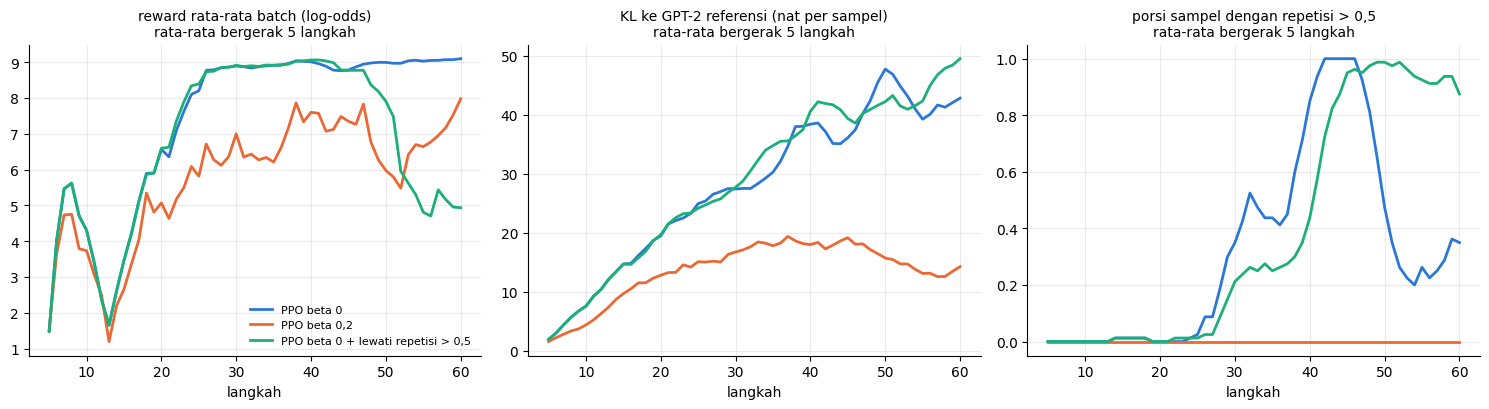

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
colors = {"PPO beta 0": "#2a78d6", "PPO beta 0,2": "#eb6834", SKIP: "#1baf7a"}
for k, color in colors.items():
    h = hists[k]
    w = min(5, len(h))
    x = np.arange(w, len(h) + 1)
    for ax, j in zip(axes, range(3)):
        ax.plot(x, np.convolve(h[:, j], np.ones(w) / w, mode="valid"), color=color, lw=2, label=k)   # rata-rata bergerak 5 langkah
titles = ("reward rata-rata batch (log-odds)", "KL ke GPT-2 referensi (nat per sampel)", "porsi sampel dengan repetisi > 0,5")
for ax, title in zip(axes, titles):
    ax.set_title(title + "\nrata-rata bergerak 5 langkah", fontsize=10)
    ax.set_xlabel("langkah")
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Di run referensi hasilnya kebalikan dari hipotesis.** Lengan dengan batasan berakhir dengan **semua** respons evaluasi berulang (lawan 0,586 tanpa batasan dan 0,008 dengan penalti KL), berisi *amazing amazing amazing ... exciting amazing*: hanya sekitar 29 token berbeda di 2.048 token respons (distinct-1 0,014). Reward tetap 8,53 dan VADER 0,93. Plot run itu memperlihatkan mekanismenya: sampel berulang pertama muncul di langkah 26 pada kedua lengan β = 0, lalu lengan dengan batasan lebih cepat jatuh ke repetisi sampai semua sampelnya melanggar. Di 10 langkah terakhir tak ada update sama sekali, dan policy membeku dalam keadaan yang sudah diretas.

**Run validasi tidak mengulang pembekuan itu.** Sampel berulang pertama juga muncul bersamaan pada kedua lengan (langkah 29), tapi hanya 3% sampel latih yang dilewati. Lengan dengan batasan tetap berakhir dengan lebih banyak respons berulang (21% lawan 3%), padahal pola itulah yang disaringnya; di metrik lain keduanya hampir sama buruk (reward 8,87 lawan 8,74, distinct-1 0,074 lawan 0,055). Yang konsisten di kedua run: batasan tidak mencegah reward hacking. Seberapa parah hasilnya, dan apakah policy sampai membeku, bergantung pada lintasan acak.

**Kenapa batasan ini gagal?** Melewati update tidak memberi sinyal apa pun pada sampel yang melanggar; ia hanya membuangnya, dan begitu semua sampel melanggar, belajar berhenti. Normalisasi advantage per grup bisa memperparah: bila sampel berulang ber-reward lebih tinggi, sampel yang tidak berulang di grup yang sama mendapat advantage negatif (andilnya tidak dipisahkan di sini). Agar policy menjauhi pelanggaran, pelanggaran harus masuk ke objektif, misalnya sebagai penalti di skor seperti KL pada lengan β = 0,2. Di output Anda, lihat kolom `ulang>0,5`, distinct-1, dan jumlah langkah tanpa update.

## Penerapan RLHF: meringkas teks

Buku mendaftar penerapan RLHF (generasi teks terbuka, sistem dialog, moderasi konten, ringkasan, dan generasi kode) dan memberi contoh untuk ringkasan: buat ringkasan, nilai dengan reward model, perbarui model, ulangi.

> **Listing buku: `rlhf_summarization` — perlu diperbaiki**
>
> ```python
> prompt = f"Summarize the following text:\n{text}\n\nSummary:"
> for _ in range(num_iterations):
>     summary = base_model.generate(prompt, max_length=100)
>     reward = reward_model(summary)
>     # Update base_model using PPO or another RL algorithm
>     # ...
> summary = rlhf_summarization(base_model, reward_model, long_text)   # contoh pemakaian
> ```
>
> Contoh pemakaiannya berhenti di `NameError: name 'reward_model' is not defined`, karena reward model tak pernah didefinisikan di level modul. Setelah itu muncul tiga masalah lagi: prompt string ke `generate` (`AttributeError`), `summary` berupa tensor id token (prompt + lanjutan) yang diberikan ke reward model, dan `max_length=100` yang ikut menghitung prompt, sehingga pada paragraf nyata `generate` menolak dengan `ValueError: Input length of input_ids is ..., but max_length is set to 100`. Update-nya hanya komentar. Versi yang berjalan ada di sel berikut.

Perbaikannya: prompt ditokenisasi di GPU, panjang ringkasan dibatasi dengan `max_new_tokens=60`, dan hanya token baru yang di-decode; update tetap kosong seperti di buku. Base model-nya GPT-2 124M referensi (`ref_lm`), dan reward-nya classifier sentimen yang sama (buku tak menyediakan reward model ringkasan, jadi reward ini tak mengukur kualitas ringkasan). Teksnya paragraf wikitext-2 pertama yang lebih dari 120 kata.

In [27]:
def rlhf_summarization(base_model, reward_model, text, num_iterations=5, max_new_tokens=60):
    prompt = f"Summarize the following text:\n{text}\n\nSummary:"
    inputs = gpt_tok(prompt, return_tensors="pt").to(DEVICE)                     # perbaikan: id token di DEVICE
    summaries, rewards = [], []
    for _ in range(num_iterations):
        with torch.no_grad():
            out = base_model.generate(**inputs, max_new_tokens=max_new_tokens,   # perbaikan: max_new_tokens
                                      pad_token_id=gpt_tok.eos_token_id)
        summary = gpt_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)   # perbaikan: hanya token baru
        summaries.append(summary)
        rewards.append(reward_model(summary))
        # Update base_model using PPO or another RL algorithm -- tetap kosong seperti di buku
    return summaries, rewards


real_text = next(p.strip() for p in wiki_val["text"] if len(p.split()) > 120 and not p.strip().startswith("="))
n_prompt = len(gpt_tok(f"Summarize the following text:\n{real_text}\n\nSummary:")["input_ids"])
summaries, rewards = rlhf_summarization(ref_lm, reward_fn, real_text)
print(f"teks sumber {len(real_text.split())} kata, prompt {n_prompt} token | lima iterasi identik: {len(set(summaries)) == 1} | "
      f"reward per iterasi {[round(x, 2) for x in rewards]}")
print(f"\nsumber (awal): {real_text[:300]!r}...")
print(f"ringkasan:     {summaries[-1]!r}")
print(f"\nkata ringkasan yang juga ada di teks sumber: {np.mean([w in real_text.split() for w in summaries[-1].split()]):.3f}")
for sentence in [s.strip() for s in summaries[-1].split(" . ") if s.strip()]:
    print(f"   kalimat muncul kata per kata di sumber: {sentence in real_text!s:<5} | {sentence[:70]!r}")

teks sumber 141 kata, prompt 167 token | lima iterasi identik: True | reward per iterasi [-0.82, -0.82, -0.82, -0.82, -0.82]

sumber (awal): 'Homarus gammarus , known as the European lobster or common lobster , is a species of clawed lobster from the eastern Atlantic Ocean , Mediterranean Sea and parts of the Black Sea . It is closely related to the American lobster , H. americanus . It may grow to a length of 60 cm ( 24 in ) and a mass o'...
ringkasan:     ' Homarus gammarus is a common lobster that is found in the Mediterranean Sea and parts of the Black Sea . It is closely related to the American lobster , H. americanus . It may grow to a length of 60 cm ( 24 in ) and a mass of 6 kilograms ( 13 lb )'

kata ringkasan yang juga ada di teks sumber: 0.964
   kalimat muncul kata per kata di sumber: False | 'Homarus gammarus is a common lobster that is found in the Mediterranea'
   kalimat muncul kata per kata di sumber: True  | 'It is closely related to the American lobster , H. american

**Lima iterasi, lima ringkasan identik.** Tanpa update dan dengan decoding greedy, setiap iterasi mengulang perhitungan yang sama, sehingga ringkasan dan reward-nya (−0,82 di run referensi) tak pernah berubah. Padahal buku menjanjikan ringkasan yang membaik dari iterasi ke iterasi.

**Ringkasannya pun nyaris salinan.** Teks sumber tentang lobster Eropa dibuka dengan *Homarus gammarus , known as the European lobster or common lobster , is a species of clawed lobster ...*. Di run referensi, GPT-2 memadatkan kalimat pertama menjadi *Homarus gammarus is a common lobster that is found in the Mediterranean Sea and parts of the Black Sea*, lalu menyalin dua kalimat berikutnya kata per kata; 96% kata ringkasannya ada di teks sumber. GPT-2 tanpa instruction tuning tidak benar-benar mengikuti instruksi *Summarize*; ia melanjutkan teks yang baru dibacanya.

## Ringkasan bab

Buku menutup bab dengan mencatat bahwa RLHF dipakai penyedia model frontier, dengan keterbatasan utama di skala umpan balik manusia, dan menyebut RL tanpa umpan balik manusia dari DeepSeek sebagai topik di luar cakupan buku. Pengukuran di notebook ini menambah pelajaran berikut:

- **Reward model.** Reward model harus membaca teks dengan tokenizer-nya sendiri; kalau tidak, sebagian teks berakhir dengan error dan sisanya diberi skor tak bermakna. Pada data preferensi manusia, reward model sederhana kita tak terbukti lebih baik dari aturan "pilih jawaban yang lebih panjang", jadi bandingkan reward model dengan baseline panjang, bukan dengan 0,5.
- **Loop RL dan penalti KL.** `ppo_step` tak bisa melatih, dan loss-nya mendorong distribusi token ke seragam. Loop yang benar tanpa penalti KL meretas classifier sentimen dalam 60 langkah di kedua run, dan penilai sentimen kedua ikut tertipu; penalti KL menahannya dengan biaya sebagian reward.
- **DPO.** Setelah empat perbaikan API, DPO berjalan, tapi pada anggaran sekitar 80 langkah learning rate bawaannya praktis tak mengubah model. Dengan learning rate lebih besar, DPO mencapai reward lebih rendah dari loop RL pada KL yang juga lebih rendah, tanpa reward hacking, sementara labelnya tetap berasal dari reward model.
- **Skala.** Gradient checkpointing hanya bekerja di mode train, dan manfaat mixed precision bergantung pada hardware.
- **Keterbatasan.** Membuang sampel yang melanggar batasan tidak mengajari policy apa pun; di kedua run, lengan dengan batasan tetap meretas reward. Pelanggaran harus masuk ke objektif.
- **Penerapan.** Tanpa update, "RLHF untuk ringkasan" hanya mengulang decoding greedy yang sama, dan GPT-2 dasar cenderung menyalin teks sumber alih-alih meringkas.

Bab berikutnya di buku membahas prompt engineering lanjutan; model dasar yang menyalin alih-alih mengikuti instruksi adalah jembatan yang pas ke sana.